In [1]:
import os
from io import StringIO
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series analysis
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from pandas.plotting import lag_plot

# Forecasting models
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

from tabulate import tabulate

try:
    from prophet import Prophet
    PROPHET_AVAILABLE = True
except Exception as e:
    PROPHET_AVAILABLE = False
    print("Prophet is not available in this environment.")
    print("Install it with: !pip install prophet")
    print("Import error:", e)

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# Part 1: Self-Collected Data Analysis — Daily Step Counts

In [2]:
# Path to the CSV file
file_path = "schritte_tageswerte.csv"

# Read the CSV file
df = pd.read_csv(file_path)

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Sort by date
df = df.sort_values("date").reset_index(drop=True)

# Show preview
print(df.head())

        date  steps
0 2026-03-01  11092
1 2026-03-02  13256
2 2026-03-03  10638
3 2026-03-04  15563
4 2026-03-05  13761


In [3]:
# Convert the date column to datetime format
df["date"] = pd.to_datetime(df["date"])

# Sort data by date (important for plotting and time series analysis) and reset index
df = df.sort_values("date").reset_index(drop=True)

# Show the first 5 entries
df.head()

,date,steps
0,2026-03-01,11092
1,2026-03-02,13256
2,2026-03-03,10638
3,2026-03-04,15563
4,2026-03-05,13761


#### Descriptive statistics

In [4]:
# Calculate and round descriptive statistics

desc_stats = df["steps"].describe()[["mean", "50%", "std", "min", "max"]].round(0)

# Create DataFrame for table
desc_df = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Standard Deviation", "Minimum", "Maximum"],
    "Value (Steps)": desc_stats.values.astype(int)
})

# Generate and print formatted table using tabulate
print("\nDescriptive Statistics of Daily Steps:\n")
print(tabulate(desc_df, headers="keys", tablefmt="grid", showindex=False))


Descriptive Statistics of Daily Steps:

+--------------------+-----------------+
| Statistic          |   Value (Steps) |
+====================+=================+
| Mean               |           12686 |
+--------------------+-----------------+
| Median             |           12299 |
+--------------------+-----------------+
| Standard Deviation |            1892 |
+--------------------+-----------------+
| Minimum            |           10143 |
+--------------------+-----------------+
| Maximum            |           17251 |
+--------------------+-----------------+


#### Time series plot

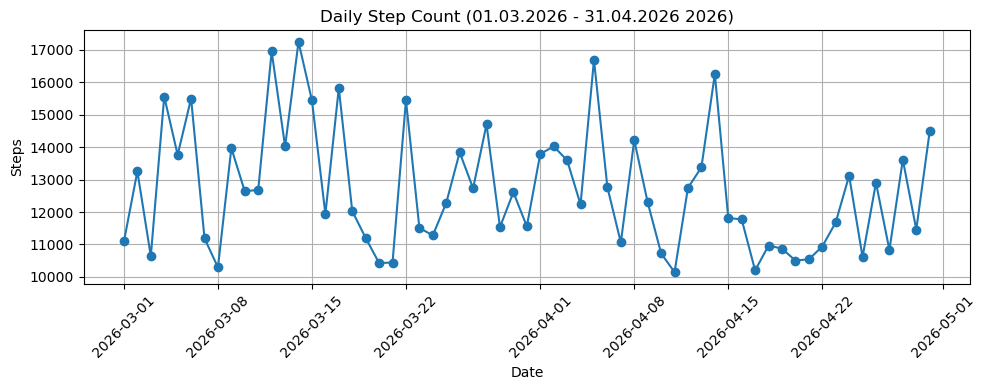

In [5]:
# Create time series plot

plt.figure(figsize=(10, 4))
plt.plot(df["date"], df["steps"], marker='o', linestyle='-')

# Add title and labels
plt.title("Daily Step Count (01.03.2026 - 31.04.2026 2026)")
plt.xlabel("Date")
plt.ylabel("Steps")
plt.grid(True)

# Improve x-axis readability
plt.xticks(rotation=45)
plt.tight_layout()

# Show the plot
plt.show()

#### Missing values / timestamps

In [6]:
# Check for missing values in the columns

print("Missing values in each column:")
print(df.isnull().sum())

# Create a complete daily date range based on the dataset
full_range = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

# Identify missing dates by comparing expected range with actual dates
missing_dates = full_range.difference(df["date"])

# Create DataFrame for missing dates
missing_dates_df = pd.DataFrame({"missing_date": missing_dates})

print("\nMissing dates in the time series:")

if missing_dates_df.empty:
    print("No missing dates found.")
else:
    display(missing_dates_df)

Missing values in each column:
date     0
steps    0
dtype: int64

Missing dates in the time series:
No missing dates found.


#### Outliers / anomalies

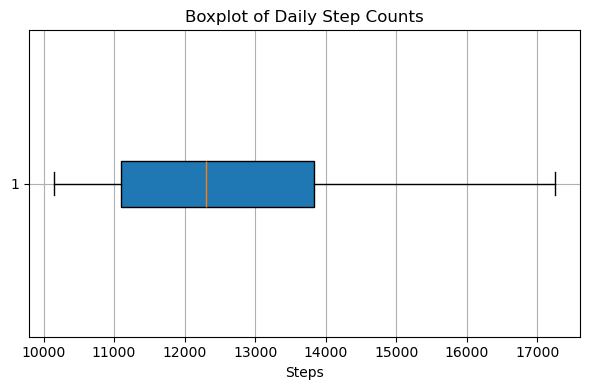

In [7]:
# Create a boxplot for the step counts

plt.figure(figsize=(6, 4))
plt.boxplot(df["steps"], vert=False, patch_artist=True)
plt.title("Boxplot of Daily Step Counts")
plt.xlabel("Steps")
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
# Calculate the first (Q1) and third (Q3) quartile

Q1 = df["steps"].quantile(0.25)
Q3 = df["steps"].quantile(0.75)
IQR = Q3 - Q1  # Interquartile Range

# Define lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out the potential outliers
outliers = df[(df["steps"] < lower_bound) | (df["steps"] > upper_bound)]

# Show the detected outliers
print("Potential outliers detected:")
print(outliers)
print(f"Lower bound: {lower_bound:.0f} steps")
print(f"Upper bound: {upper_bound:.0f} steps")
print(f"Number of potential outliers: {len(outliers)}")

outliers

Potential outliers detected:
Empty DataFrame
Columns: [date, steps]
Index: []
Lower bound: 6970 steps
Upper bound: 17962 steps
Number of potential outliers: 0


,date,steps


### 3.2 Serial Dependence and Temporal Structure Analysis

#### ACF and PACF Analysis

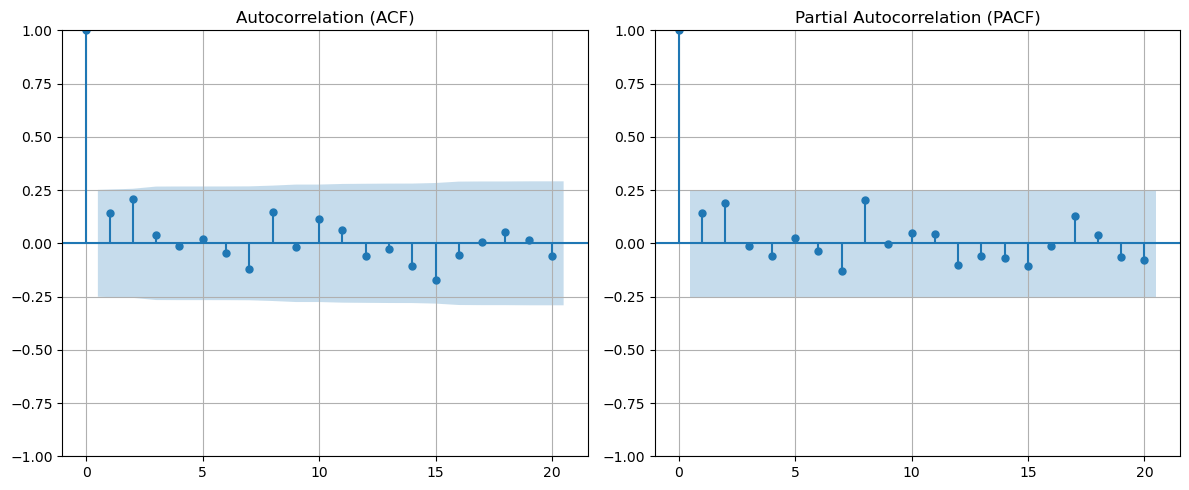

In [9]:
# Create subplots for ACF and PACF

plt.figure(figsize=(12, 5))

# Use sorted daily step series
steps_series = df.sort_values("date")["steps"].dropna()

# ACF (Autocorrelation Function)
plt.subplot(1, 2, 1)
plot_acf(steps_series, lags=20, ax=plt.gca())
plt.title("Autocorrelation (ACF)")

# PACF (Partial Autocorrelation Function)
plt.subplot(1, 2, 2)
plot_pacf(steps_series, lags=20, ax=plt.gca(), method="ywm")
plt.title("Partial Autocorrelation (PACF)")

plt.tight_layout()
plt.show()

#### Weekday Pattern Analysis

In [10]:
# Add a new column with the weekday name, e.g. "Monday"

df["Weekday"] = df["date"].dt.day_name()

# Check the DataFrame

df[["date", "steps", "Weekday"]].head()

,date,steps,Weekday
0,2026-03-01,11092,Sunday
1,2026-03-02,13256,Monday
2,2026-03-03,10638,Tuesday
3,2026-03-04,15563,Wednesday
4,2026-03-05,13761,Thursday


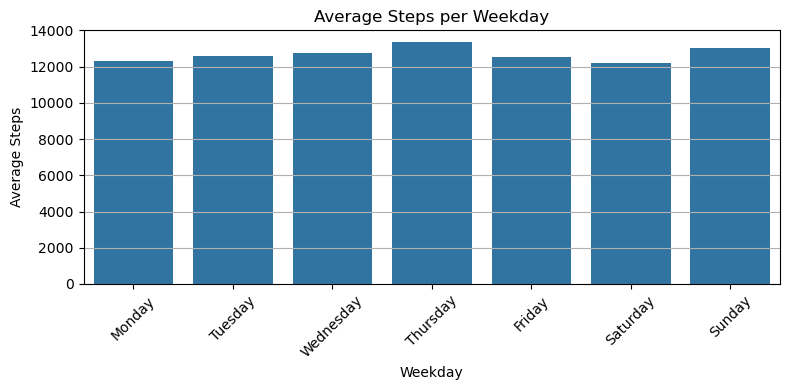

In [11]:
# Compute mean steps per weekday

weekday_avg = df.groupby("Weekday")["steps"].mean().reindex([
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
])

# Display as bar chart
plt.figure(figsize=(8, 4))
sns.barplot(x=weekday_avg.index, y=weekday_avg.values)
plt.title("Average Steps per Weekday")
plt.ylabel("Average Steps")
plt.xlabel("Weekday")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

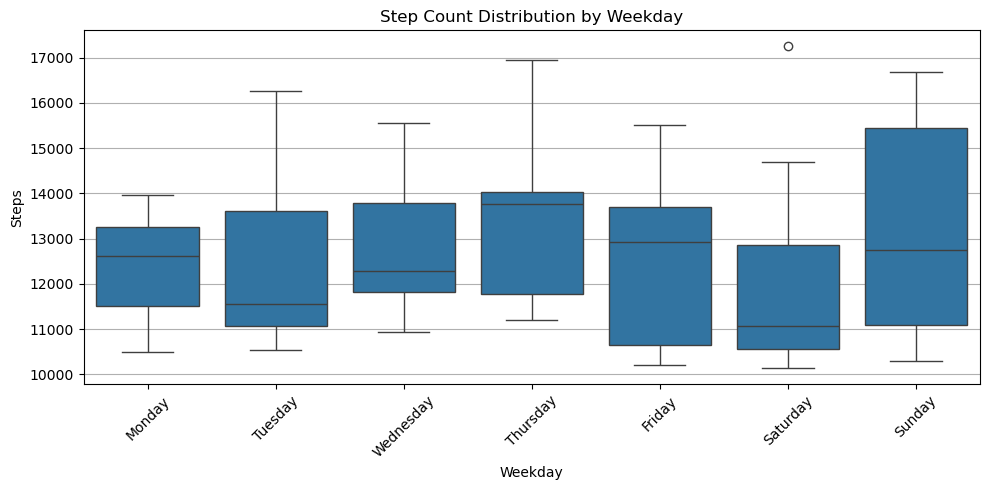

In [12]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="Weekday",
    y="steps",
    order=[
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ]
)

plt.title("Step Count Distribution by Weekday")
plt.ylabel("Steps")
plt.xlabel("Weekday")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Lag Plot Analysis

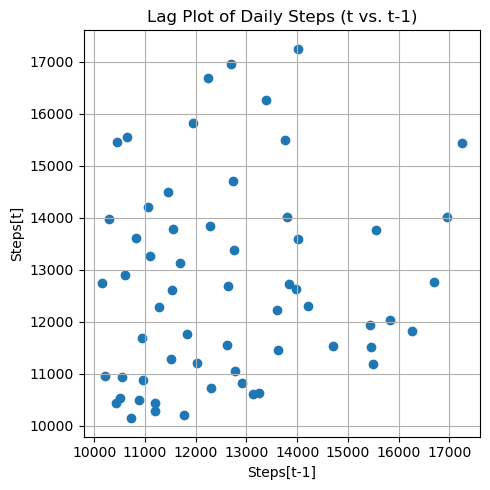

In [13]:
# Prepare sorted step series

steps_series = df.sort_values("date")["steps"].dropna()

# Plot lag-1 plot (steps[t] vs steps[t-1])
plt.figure(figsize=(5, 5))
lag_plot(steps_series)
plt.title("Lag Plot of Daily Steps (t vs. t-1)")
plt.xlabel("Steps[t-1]")
plt.ylabel("Steps[t]")
plt.grid(True)
plt.tight_layout()
plt.show()

#### Rolling Statistics Analysis

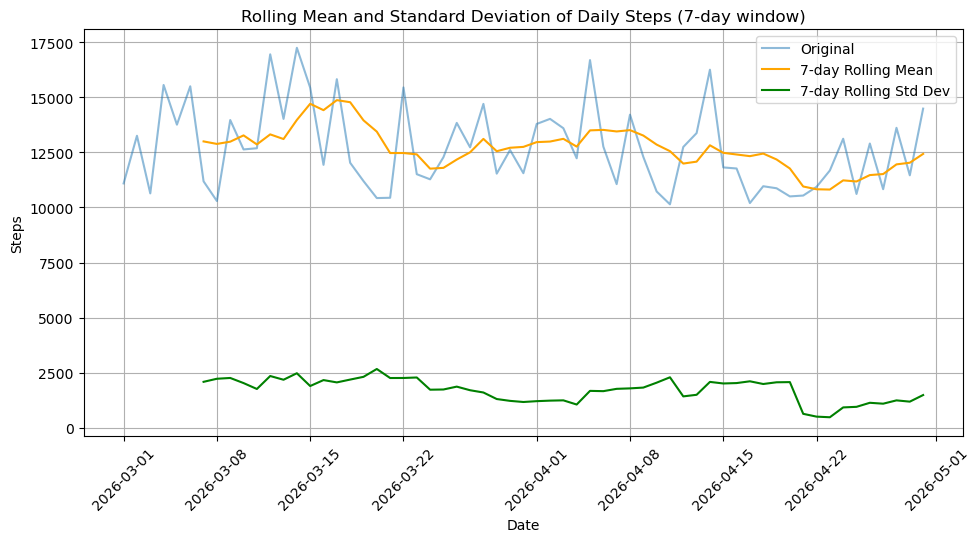

In [14]:
# Sort data by date

df = df.sort_values("date").reset_index(drop=True)

# Rolling window size (7 days)
rolling_window = 7

# Calculate rolling mean and standard deviation
rolling_mean = df["steps"].rolling(window=rolling_window).mean()
rolling_std = df["steps"].rolling(window=rolling_window).std()

# Plot
plt.figure(figsize=(10, 5))
plt.plot(df["date"], df["steps"], label="Original", alpha=0.5)
plt.plot(df["date"], rolling_mean, label=f"{rolling_window}-day Rolling Mean", color="orange")
plt.plot(df["date"], rolling_std, label=f"{rolling_window}-day Rolling Std Dev", color="green")

plt.title("Rolling Mean and Standard Deviation of Daily Steps (7-day window)")
plt.xlabel("Date")
plt.ylabel("Steps")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

### 3.3 Pattern Identification, Decomposition, and Stationarity Check

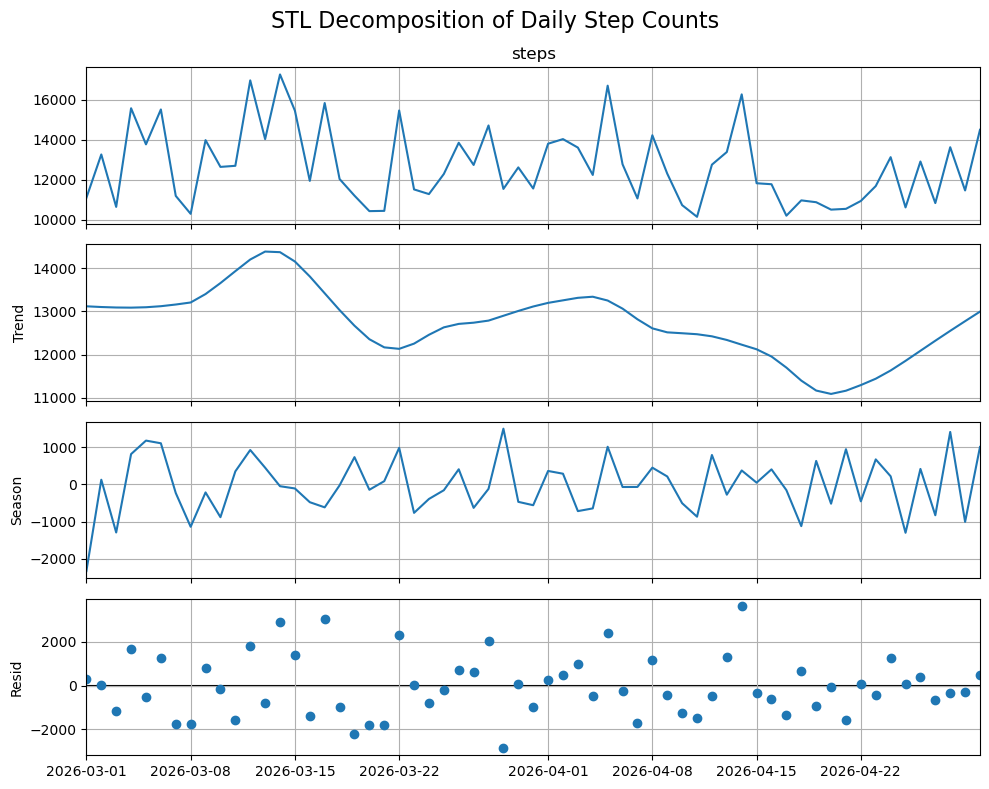

In [15]:
# Prepare daily step time series

ts = (
    df.sort_values("date")
      .set_index("date")["steps"]
      .asfreq("D")
)

# Apply STL decomposition with weekly seasonality
stl = STL(ts.dropna(), period=7)  # 7 = weekly seasonality for daily data
res = stl.fit()

# Plot the decomposition
res.plot()
plt.gcf().set_size_inches(10, 8)
plt.suptitle("STL Decomposition of Daily Step Counts", fontsize=16)
plt.tight_layout()
plt.show()

# Part 2 Public Dataset Analysis - Microgrid Energy Forecasting

This notebook prepares the public microgrid energy dataset for exploratory time series analysis and forecasting

Main decisions in this version:

- The only forecasting target is `load_demand`
- The raw dataset is recorded every 15 minutes
- The notebook converts the data to hourly frequency immediately after loading
- All EDA, decomposition, stationarity analysis, train-test split and models use the hourly dataset
- Model order:
  1. Holt-Winters
  2. SARIMA
  3. Prophet

In [16]:
DATA_PATH = Path("microgrid_energy_dataset.csv")

TARGET = "load_demand"
TIMESTAMP_COL = "timestamp"

# Raw data frequency and notebook working frequency

RAW_FREQUENCY = "15min"
RESAMPLE_RULE = "h"

# Hourly data has 24 observations per day

SEASONAL_PERIOD = 24

# Chronological test split: last 20 percent of observations

TEST_SIZE = 0.20

print("Target variable:", TARGET)
print("Raw data frequency:", RAW_FREQUENCY)
print("Notebook working frequency:", RESAMPLE_RULE)
print("Seasonal period:", SEASONAL_PERIOD)

Target variable: load_demand
Raw data frequency: 15min
Notebook working frequency: h
Seasonal period: 24


## 1. Load raw data and convert to hourly data

The original CSV is kept as `df_raw` for traceability

After timestamp parsing and validation, the notebook creates `df_hourly` and then assigns it to `df`

From this point onward, `df` is the hourly dataset used in the full notebook

In [17]:
# 1.1 Load raw CSV

if not DATA_PATH.exists():
    fallback_path = Path("/mnt/data/microgrid_energy_dataset.csv")
    if fallback_path.exists():
        DATA_PATH = fallback_path
    else:
        raise FileNotFoundError(
            "CSV file not found. Place microgrid_energy_dataset.csv in the same folder as this notebook."
        )

df_raw = pd.read_csv(DATA_PATH)

print("Loaded file:", DATA_PATH)
print("Raw shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes.to_frame("dtype"))

Loaded file: microgrid_energy_dataset.csv
Raw shape: (5787, 22)


,timestamp,solar_power_output,wind_power_output,solar_irradiance,temperature,wind_speed,humidity,cloud_cover,battery_soc,battery_charge_power,battery_discharge_power,grid_import_power,grid_export_power,electricity_price,grid_frequency,voltage_level,load_demand,hour_of_day,day_of_week,total_power_generation,optimal_energy_dispatch,energy_status
0,2023-01-01 00:00:00,187.270059,245.903101,781.490243,21.778581,19.512661,64.698123,62.304950,14.233930,99.047397,112.978946,191.791394,34.629431,9.552094,50.458388,219.513799,289.666915,0,6,433.173160,143.506245,Surplus
1,2023-01-01 00:15:00,475.357153,299.805090,151.587912,42.542297,12.155464,58.776221,43.925173,80.548182,160.419731,120.660238,10.638933,85.723650,4.573794,49.659653,211.940917,353.372938,0,6,775.162243,421.789305,Surplus
2,2023-01-01 00:30:00,365.996971,63.429377,647.159561,20.735491,15.621955,53.879603,80.791870,50.879598,186.779939,58.571368,195.257503,162.276762,6.073084,50.174570,245.289773,141.904436,0,6,429.426348,287.521912,Surplus
3,2023-01-01 00:45:00,299.329242,79.551222,917.425853,38.848528,8.997294,61.558963,69.061121,43.886652,53.952267,197.589923,37.532051,37.931966,4.146472,49.735096,227.557229,191.342016,0,6,378.880464,187.538448,Surplus
4,2023-01-01 01:00:00,78.009320,198.857936,679.836760,44.000180,10.640146,32.942859,11.146919,50.222916,26.038736,157.107583,356.985064,336.325469,10.307233,49.635554,234.842253,527.154247,1,6,276.867257,-250.286990,Deficit


,dtype
timestamp,object
solar_power_output,float64
wind_power_output,float64
solar_irradiance,float64
temperature,float64
wind_speed,float64
humidity,float64
cloud_cover,float64
battery_soc,float64
battery_charge_power,float64


In [18]:
# 1.2 Parse timestamps and validate raw 15-minute structure

df_15min = df_raw.copy()

if TIMESTAMP_COL not in df_15min.columns:
    raise ValueError(f"Timestamp column '{TIMESTAMP_COL}' not found.")

df_15min[TIMESTAMP_COL] = pd.to_datetime(df_15min[TIMESTAMP_COL], errors="coerce")

invalid_timestamps = df_15min[TIMESTAMP_COL].isna().sum()
if invalid_timestamps > 0:
    raise ValueError(f"Invalid timestamps found: {invalid_timestamps}")

df_15min = df_15min.sort_values(TIMESTAMP_COL).set_index(TIMESTAMP_COL)

print("Raw start:", df_15min.index.min())
print("Raw end:", df_15min.index.max())
print("Raw observations:", len(df_15min))
print("Duplicated raw timestamps:", df_15min.index.duplicated().sum())

time_diffs = df_15min.index.to_series().diff().dropna()
display(time_diffs.value_counts().head(10).to_frame("count"))

raw_missing_summary = pd.DataFrame({
    "missing_count": df_15min.isna().sum(),
    "missing_share": df_15min.isna().mean()
}).sort_values("missing_count", ascending=False)

display(raw_missing_summary)

Raw start: 2023-01-01 00:00:00
Raw end: 2023-03-02 06:30:00
Raw observations: 5787
Duplicated raw timestamps: 0


,count
timestamp,
0 days 00:15:00,5786


,missing_count,missing_share
solar_power_output,0,0.0
grid_export_power,0,0.0
optimal_energy_dispatch,0,0.0
total_power_generation,0,0.0
day_of_week,0,0.0
hour_of_day,0,0.0
load_demand,0,0.0
voltage_level,0,0.0
grid_frequency,0,0.0
electricity_price,0,0.0


In [19]:
# 1.3 Convert the full dataset from 15-minute frequency to hourly frequency

def mode_or_first(values):
    values = values.dropna()
    if values.empty:
        return np.nan
    mode_values = values.mode()
    if not mode_values.empty:
        return mode_values.iloc[0]
    return values.iloc[0]

numeric_cols_raw = df_15min.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols_raw = df_15min.select_dtypes(exclude=[np.number]).columns.tolist()

df_hourly_numeric = df_15min[numeric_cols_raw].resample(RESAMPLE_RULE).mean()

if categorical_cols_raw:
    df_hourly_categorical = df_15min[categorical_cols_raw].resample(RESAMPLE_RULE).agg(mode_or_first)
    df_hourly = pd.concat([df_hourly_numeric, df_hourly_categorical], axis=1)
else:
    df_hourly = df_hourly_numeric.copy()

# Enforce a complete hourly index

expected_hourly_index = pd.date_range(
    start=df_hourly.index.min(),
    end=df_hourly.index.max(),
    freq=RESAMPLE_RULE
)
df_hourly = df_hourly.reindex(expected_hourly_index)
df_hourly.index.name = TIMESTAMP_COL

# Fill gaps only if hourly gaps exist

hourly_missing_before = df_hourly.isna().sum()

numeric_cols_hourly = df_hourly.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols_hourly = df_hourly.select_dtypes(exclude=[np.number]).columns.tolist()

df_hourly[numeric_cols_hourly] = (
    df_hourly[numeric_cols_hourly]
    .interpolate(method="time")
    .ffill()
    .bfill()
)

for col in categorical_cols_hourly:
    df_hourly[col] = df_hourly[col].ffill().bfill()

# Recalculate time feature columns after hourly aggregation

if "hour_of_day" in df_hourly.columns:
    df_hourly["hour_of_day"] = df_hourly.index.hour

if "day_of_week" in df_hourly.columns:
    df_hourly["day_of_week"] = df_hourly.index.dayofweek

df = df_hourly.copy()

print("Hourly start:", df.index.min())
print("Hourly end:", df.index.max())
print("Hourly observations:", len(df))
print("Hourly frequency:", pd.infer_freq(df.index))
print("Target present:", TARGET in df.columns)

display(hourly_missing_before.sort_values(ascending=False).to_frame("missing_before_fill").head(20))
display(df.head())

Hourly start: 2023-01-01 00:00:00
Hourly end: 2023-03-02 06:00:00
Hourly observations: 1447
Hourly frequency: h
Target present: True


,missing_before_fill
solar_power_output,0
grid_export_power,0
optimal_energy_dispatch,0
total_power_generation,0
day_of_week,0
hour_of_day,0
load_demand,0
voltage_level,0
grid_frequency,0
electricity_price,0


,solar_power_output,wind_power_output,solar_irradiance,temperature,wind_speed,humidity,cloud_cover,battery_soc,battery_charge_power,battery_discharge_power,grid_import_power,grid_export_power,electricity_price,grid_frequency,voltage_level,load_demand,hour_of_day,day_of_week,total_power_generation,optimal_energy_dispatch,energy_status
timestamp,,,,,,,,,,,,,,,,,,,,,
2023-01-01 00:00:00,331.988356,172.172198,624.415892,30.976224,14.071844,59.728227,64.020778,47.387091,125.049833,122.450118,108.804970,80.140452,6.086361,50.006927,226.075430,244.071577,0,6,504.160554,260.088977,Surplus
2023-01-01 01:00:00,154.534115,228.524872,462.640476,40.032565,12.576767,45.392795,34.743342,67.379007,73.251111,109.174826,242.609036,205.034973,8.342786,49.834198,240.589893,324.497600,1,6,383.058987,58.561387,Deficit
2023-01-01 02:00:00,287.460242,215.448567,728.241257,20.647306,7.528071,63.983798,61.453691,63.703336,72.867761,83.632385,143.885639,89.687486,7.049558,50.158517,240.209911,347.590835,2,6,502.908809,155.317974,Surplus
2023-01-01 03:00:00,176.251404,62.626851,480.477991,30.935416,13.856830,58.023830,28.389931,47.655649,103.509884,145.089441,174.972059,278.253692,9.075846,50.054603,229.029884,499.471023,3,6,238.878254,-260.592769,Deficit
2023-01-01 04:00:00,194.021604,121.867042,500.761372,33.068037,16.245034,70.054461,58.988350,59.818661,75.757285,90.068409,208.490003,178.690327,7.574632,49.791334,224.635019,629.716123,4,6,315.888646,-313.827477,Deficit


## 2. Exploratory Data Analysis

This section supports Part 2.1 of the paper

All outputs in this section are based on the hourly dataset

In [20]:
# 2.1 Descriptive statistics of the hourly dataset

if TARGET not in df.columns:
    raise ValueError(f"Target '{TARGET}' not found. Available columns: {df.columns.tolist()}")

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

target_summary = df[TARGET].describe().to_frame("target_summary")
display(target_summary)

hourly_missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_share": df.isna().mean()
}).sort_values("missing_count", ascending=False)

display(hourly_missing_summary)

Numeric columns: ['solar_power_output', 'wind_power_output', 'solar_irradiance', 'temperature', 'wind_speed', 'humidity', 'cloud_cover', 'battery_soc', 'battery_charge_power', 'battery_discharge_power', 'grid_import_power', 'grid_export_power', 'electricity_price', 'grid_frequency', 'voltage_level', 'load_demand', 'hour_of_day', 'day_of_week', 'total_power_generation', 'optimal_energy_dispatch']
Categorical columns: ['energy_status']


,target_summary
count,1447.000000
mean,446.493916
std,102.741120
min,139.719226
25%,376.068599
50%,448.244564
75%,517.130617
max,738.287595


,missing_count,missing_share
solar_power_output,0,0.0
grid_export_power,0,0.0
optimal_energy_dispatch,0,0.0
total_power_generation,0,0.0
day_of_week,0,0.0
hour_of_day,0,0.0
load_demand,0,0.0
voltage_level,0,0.0
grid_frequency,0,0.0
electricity_price,0,0.0


In [21]:
# 2.2 Interactive weekly target time series plot
# Week starts on Monday at 08:00


# Make sure the index is a DatetimeIndex
df = df.copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index()

# Find the first Monday at 08:00 that is available in the dataset
first_timestamp = df.index.min()

days_until_monday = (0 - first_timestamp.weekday()) % 7
week_start = first_timestamp.normalize() + pd.Timedelta(days=days_until_monday, hours=8)

# If this Monday 08:00 is before the first available timestamp, move to the next Monday
if week_start < first_timestamp:
    week_start = week_start + pd.Timedelta(days=7)

week_end = week_start + pd.Timedelta(days=7)

# Select one complete week
weekly_df = df.loc[
    (df.index >= week_start) & (df.index < week_end),
    [TARGET]
].dropna()

# Calculate weekly average
weekly_average = weekly_df[TARGET].mean()

# German weekday labels
weekday_map_de = {
    0: "Montag",
    1: "Dienstag",
    2: "Mittwoch",
    3: "Donnerstag",
    4: "Freitag",
    5: "Samstag",
    6: "Sonntag"
}

weekly_df = weekly_df.copy()
weekly_df["weekday"] = weekly_df.index.weekday.map(weekday_map_de)
weekly_df["date"] = weekly_df.index.strftime("%d.%m.%Y")
weekly_df["time"] = weekly_df.index.strftime("%H:%M")
weekly_df["hover_label"] = (
    weekly_df["weekday"] + ", " +
    weekly_df["date"] + ", " +
    weekly_df["time"] + " Uhr"
)

# X-axis ticks: one tick per day at 08:00
tickvals = pd.date_range(start=week_start, end=week_end, freq="24h")
ticktext = [
    f"{weekday_map_de[t.weekday()]}<br>{t.strftime('%d.%m.%Y')}<br>{t.strftime('%H:%M')} Uhr"
    for t in tickvals
]

# Interactive Plotly figure
fig = go.Figure()

# Actual weekly time series
fig.add_trace(
    go.Scatter(
        x=weekly_df.index,
        y=weekly_df[TARGET],
        mode="lines",
        name=f"Hourly {TARGET}",
        line=dict(width=2, color="#4c63ff"),
        customdata=weekly_df["hover_label"],
        hovertemplate=(
            "<b>%{customdata}</b><br>"
            + f"{TARGET}: "
            + "%{y:.2f}<extra></extra>"
        )
    )
)

# Weekly average line
fig.add_trace(
    go.Scatter(
        x=weekly_df.index,
        y=[weekly_average] * len(weekly_df),
        mode="lines",
        name=f"Weekly average: {weekly_average:.2f}",
        line=dict(width=3, color="#ff5733", dash="dash"),
        hovertemplate=(
            "<b>Wochendurchschnitt</b><br>"
            + f"{TARGET}: "
            + "%{y:.2f}<extra></extra>"
        )
    )
)

# Layout
fig.update_layout(
    title=(
        f"Weekly profile of hourly {TARGET}<br>"
        f"<sup>Week from {week_start.strftime('%A, %d.%m.%Y %H:%M')} "
        f"to {week_end.strftime('%A, %d.%m.%Y %H:%M')}</sup>"
    ),
    xaxis_title="Wochentag, Datum und Uhrzeit",
    yaxis_title=TARGET,
    template="plotly_white",
    width=1200,
    height=700,
    hovermode="x unified",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    )
)

# X-axis formatting with weekday and date
fig.update_xaxes(
    tickmode="array",
    tickvals=tickvals,
    ticktext=ticktext,
    rangeslider=dict(visible=True),
    rangeselector=dict(
        buttons=list([
            dict(count=12, label="12h", step="hour", stepmode="backward"),
            dict(count=24, label="24h", step="hour", stepmode="backward"),
            dict(count=3, label="3d", step="day", stepmode="backward"),
            dict(step="all", label="Full week")
        ])
    )
)

fig.show()

# Print basic information for documentation
print(f"Selected week start: {weekday_map_de[week_start.weekday()]}, {week_start.strftime('%d.%m.%Y %H:%M')}")
print(f"Selected week end:   {weekday_map_de[week_end.weekday()]}, {week_end.strftime('%d.%m.%Y %H:%M')}")
print(f"Number of observations: {len(weekly_df)}")
print(f"Weekly average {TARGET}: {weekly_average:.2f}")

Selected week start: Montag, 02.01.2023 08:00
Selected week end:   Montag, 09.01.2023 08:00
Number of observations: 168
Weekly average load_demand: 439.12


In [22]:
# 2.3 Missing hourly timestamps check

expected_index = pd.date_range(start=df.index.min(), end=df.index.max(), freq=RESAMPLE_RULE)
missing_timestamps = expected_index.difference(df.index)

print("Expected hourly timestamps:", len(expected_index))
print("Actual hourly timestamps:", len(df.index))
print("Missing hourly timestamps:", len(missing_timestamps))

if len(missing_timestamps) > 0:
    display(pd.DataFrame({"missing_timestamp": missing_timestamps[:50]}))

Expected hourly timestamps: 1447
Actual hourly timestamps: 1447
Missing hourly timestamps: 0


IQR lower bound: 164.47557233523986
IQR upper bound: 728.7236430765126
Number of target outliers: 4
Share of target outliers: 0.0027643400138217


,load_demand
timestamp,
2023-01-07 23:00:00,139.719226
2023-01-11 02:00:00,161.345698
2023-01-22 01:00:00,160.448713
2023-02-06 19:00:00,738.287595


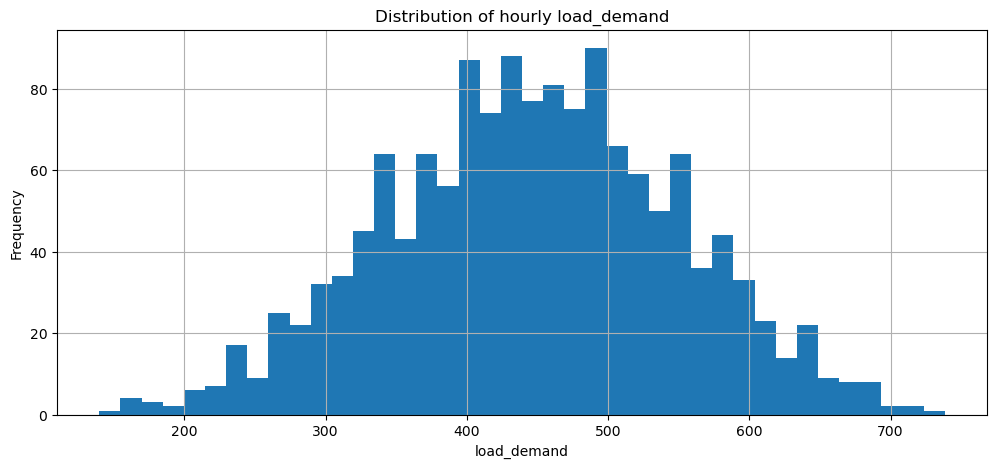

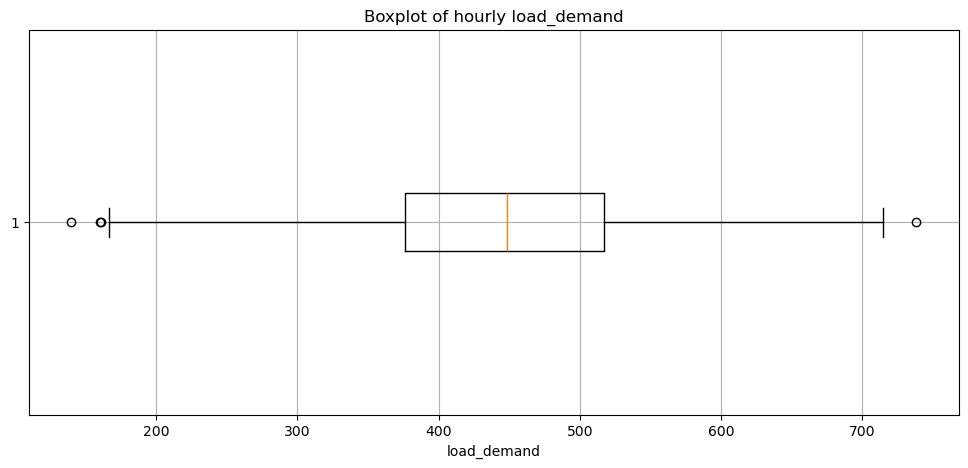

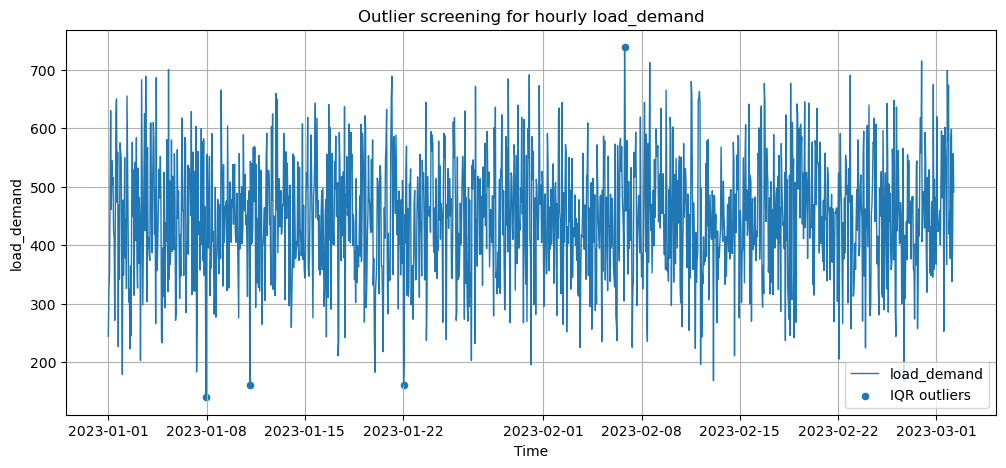

In [23]:
# 2.4 Distribution and outlier screening using IQR

q1 = df[TARGET].quantile(0.25)
q3 = df[TARGET].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df[TARGET] < lower_bound) | (df[TARGET] > upper_bound)][[TARGET]]

print("IQR lower bound:", lower_bound)
print("IQR upper bound:", upper_bound)
print("Number of target outliers:", len(outliers))
print("Share of target outliers:", len(outliers) / len(df))

display(outliers.head(20))

plt.figure()
plt.hist(df[TARGET].dropna(), bins=40)
plt.title(f"Distribution of hourly {TARGET}")
plt.xlabel(TARGET)
plt.ylabel("Frequency")
plt.show()

plt.figure()
plt.boxplot(df[TARGET].dropna(), vert=False)
plt.title(f"Boxplot of hourly {TARGET}")
plt.xlabel(TARGET)
plt.show()

plt.figure()
plt.plot(df.index, df[TARGET], label=TARGET, linewidth=1)
if len(outliers) > 0:
    plt.scatter(outliers.index, outliers[TARGET], label="IQR outliers", s=20)
plt.title(f"Outlier screening for hourly {TARGET}")
plt.xlabel("Time")
plt.ylabel(TARGET)
plt.legend()
plt.show()

## 3. Temporal structure

Because the entire notebook now works with hourly data, the temporal analysis focuses on:

- hour of day
- day of week
- daily mean values


In [24]:
# 3.1 Time-based features for the hourly dataset

eda = df.copy()
eda["hour"] = eda.index.hour
eda["day_of_week_name"] = eda.index.day_name()
eda["day_of_week_num"] = eda.index.dayofweek
eda["date"] = eda.index.date
eda["month"] = eda.index.month

display(eda[[TARGET, "hour", "day_of_week_name", "month"]].head())

,load_demand,hour,day_of_week_name,month
timestamp,,,,
2023-01-01 00:00:00,244.071577,0,Sunday,1
2023-01-01 01:00:00,324.497600,1,Sunday,1
2023-01-01 02:00:00,347.590835,2,Sunday,1
2023-01-01 03:00:00,499.471023,3,Sunday,1
2023-01-01 04:00:00,629.716123,4,Sunday,1


,mean,median,std,count
hour,,,,
0,434.729689,414.201865,106.195833,61
1,455.160897,450.664047,105.475080,61
2,434.360682,438.742337,110.210338,61
3,443.656814,439.915622,103.659196,61
4,463.052266,460.027661,101.787573,61
5,467.083909,461.089410,99.317775,61
6,444.192410,459.160936,94.305576,61
7,433.672501,436.099998,108.827118,60
8,452.993422,461.574986,98.041002,60


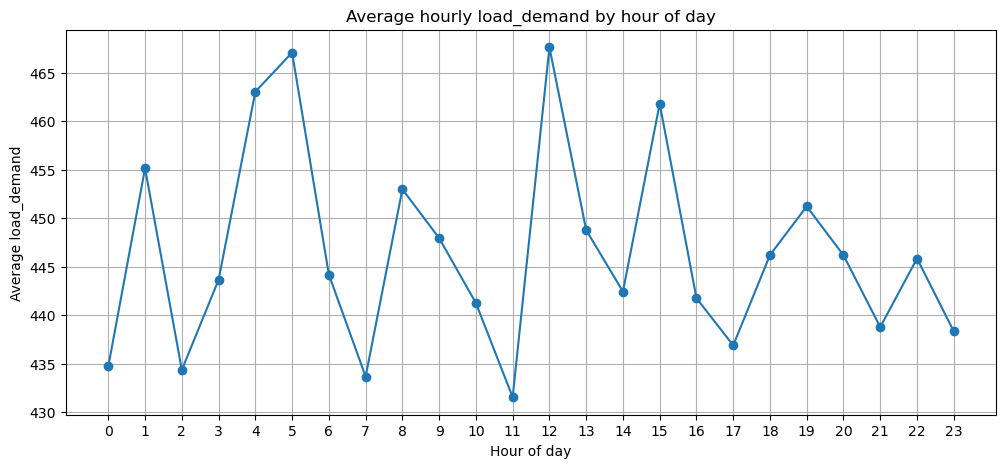

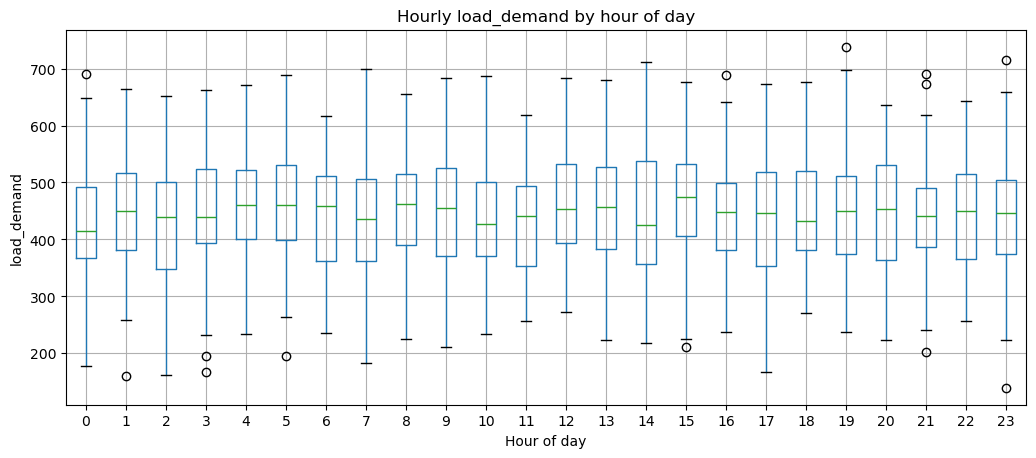

In [25]:
# 3.2 Average target by hour of day

hourly_pattern = eda.groupby("hour")[TARGET].agg(["mean", "median", "std", "count"])
display(hourly_pattern)

plt.figure()
plt.plot(hourly_pattern.index, hourly_pattern["mean"], marker="o")
plt.title(f"Average hourly {TARGET} by hour of day")
plt.xlabel("Hour of day")
plt.ylabel(f"Average {TARGET}")
plt.xticks(range(0, 24))
plt.show()


eda.boxplot(column=TARGET, by="hour", grid=True)
plt.title(f"Hourly {TARGET} by hour of day")
plt.suptitle("")
plt.xlabel("Hour of day")
plt.ylabel(TARGET)
plt.show()

,mean,median,std,count
day_of_week_name,,,,
Monday,445.225767,449.313096,102.458489,216
Tuesday,450.405371,452.728144,95.165941,216
Wednesday,450.964147,451.368244,104.323684,216
Thursday,449.472563,441.109673,105.460369,199
Friday,444.312442,448.499977,96.490824,192
Saturday,435.844266,432.738429,106.047330,192
Sunday,448.041604,453.653961,109.078930,216


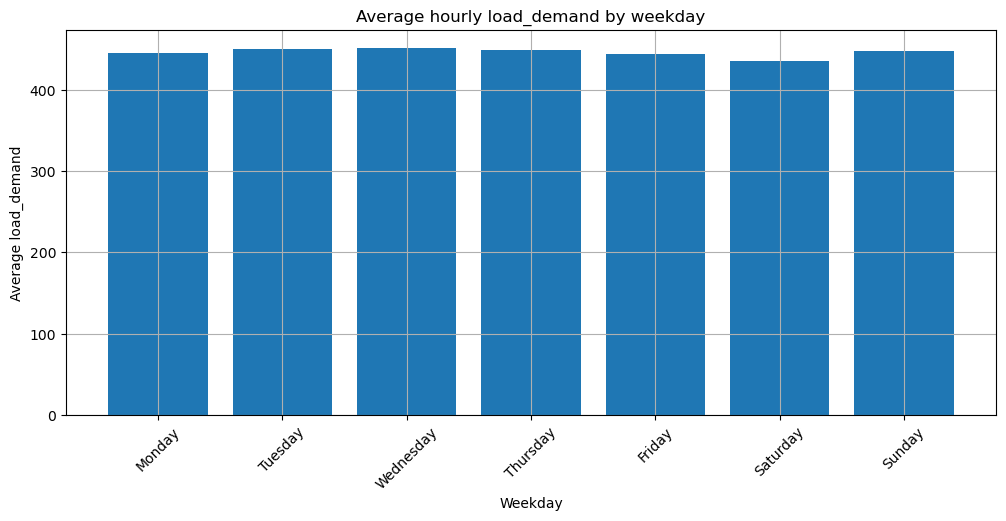

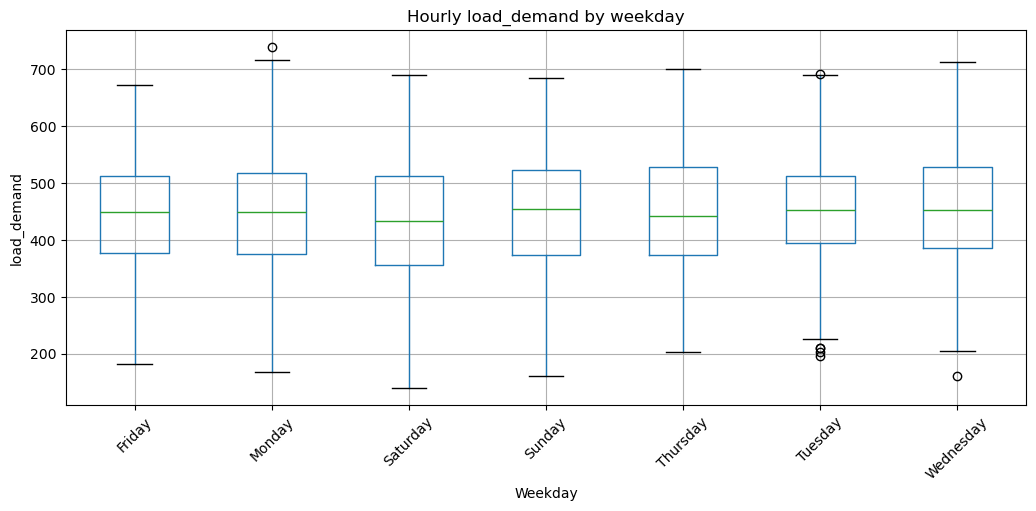

In [26]:
# 3.3 Average target by weekday

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_pattern = (
    eda.groupby("day_of_week_name")[TARGET]
    .agg(["mean", "median", "std", "count"])
    .reindex(weekday_order)
)

display(weekday_pattern)

plt.figure()
plt.bar(weekday_pattern.index, weekday_pattern["mean"])
plt.title(f"Average hourly {TARGET} by weekday")
plt.xlabel("Weekday")
plt.ylabel(f"Average {TARGET}")
plt.xticks(rotation=45)
plt.show()

eda.boxplot(column=TARGET, by="day_of_week_name", grid=True)
plt.title(f"Hourly {TARGET} by weekday")
plt.suptitle("")
plt.xlabel("Weekday")
plt.ylabel(TARGET)
plt.xticks(rotation=45)
plt.show()

All daily observations:


,daily_mean,daily_observation_count
timestamp,,
2023-01-01,457.653230,24
2023-01-02,415.600019,24
2023-01-03,448.455779,24
2023-01-04,457.536296,24
2023-01-05,434.363360,24
...,...,...
2023-02-26,426.730748,24
2023-02-27,454.525068,24
2023-02-28,453.787059,24


Complete daily observations only:


,daily_mean,daily_observation_count
timestamp,,
2023-01-01,457.653230,24
2023-01-02,415.600019,24
2023-01-03,448.455779,24
2023-01-04,457.536296,24
2023-01-05,434.363360,24
2023-01-06,457.067507,24
2023-01-07,418.225302,24
2023-01-08,416.030043,24
2023-01-09,462.529433,24


,daily_mean,daily_observation_count
count,60.000000,60.0
mean,446.341048,24.0
std,21.828793,0.0
min,392.132308,24.0
25%,432.668257,24.0
50%,447.456262,24.0
75%,457.982629,24.0
max,512.934700,24.0


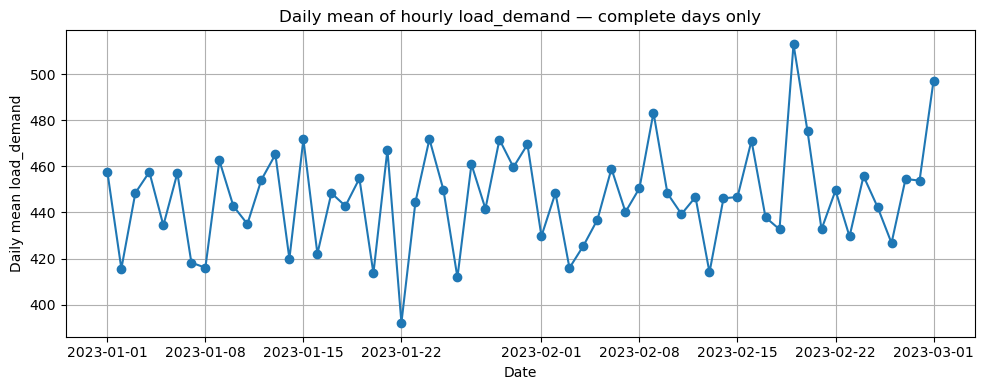

In [27]:
# 3.4 Daily summary based on hourly data
# Only complete days with 24 hourly observations are used for daily interpretation.

daily_mean = df[TARGET].resample("D").mean()
daily_count = df[TARGET].resample("D").count()

daily_summary = pd.DataFrame({
    "daily_mean": daily_mean,
    "daily_observation_count": daily_count
})

# Keep only complete days
complete_daily_summary = daily_summary[
    daily_summary["daily_observation_count"] == 24
]

print("All daily observations:")
display(daily_summary)

print("Complete daily observations only:")
display(complete_daily_summary)

display(complete_daily_summary.describe())

plt.figure(figsize=(10, 4))
plt.plot(
    complete_daily_summary.index,
    complete_daily_summary["daily_mean"],
    marker="o"
)

plt.title(f"Daily mean of hourly {TARGET} — complete days only")
plt.xlabel("Date")
plt.ylabel(f"Daily mean {TARGET}")
plt.grid(True)
plt.tight_layout()
plt.show()

## 4. Decomposition, autocorrelation and stationarity

Hourly observations: 1447
Missing values in hourly target series: 0


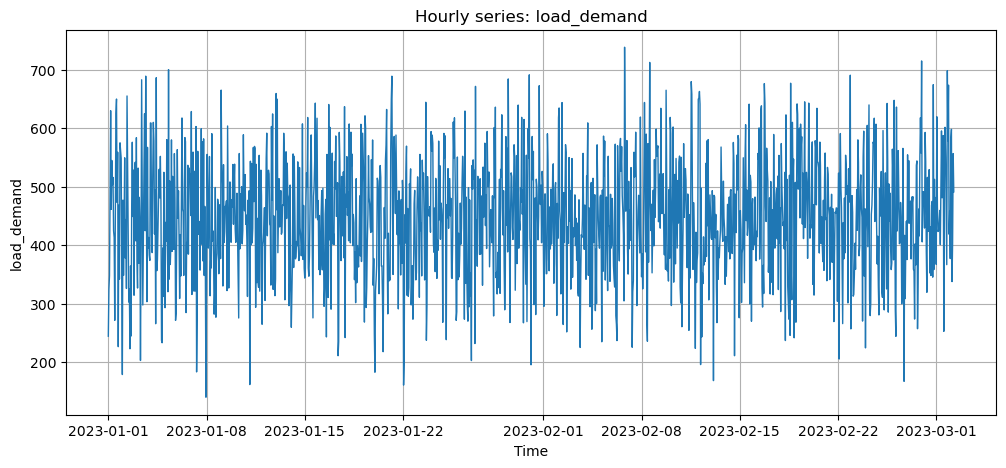

In [28]:
# 4.1 Final hourly modeling series

series_hourly = df[TARGET].astype(float).asfreq(RESAMPLE_RULE)

missing_series_values = series_hourly.isna().sum()
print("Hourly observations:", len(series_hourly))
print("Missing values in hourly target series:", missing_series_values)

if missing_series_values > 0:
    series_hourly = series_hourly.interpolate(method="time").ffill().bfill()
    print("Missing values after interpolation:", series_hourly.isna().sum())

plt.figure()
plt.plot(series_hourly.index, series_hourly.values, linewidth=1)
plt.title(f"Hourly series: {TARGET}")
plt.xlabel("Time")
plt.ylabel(TARGET)
plt.show()

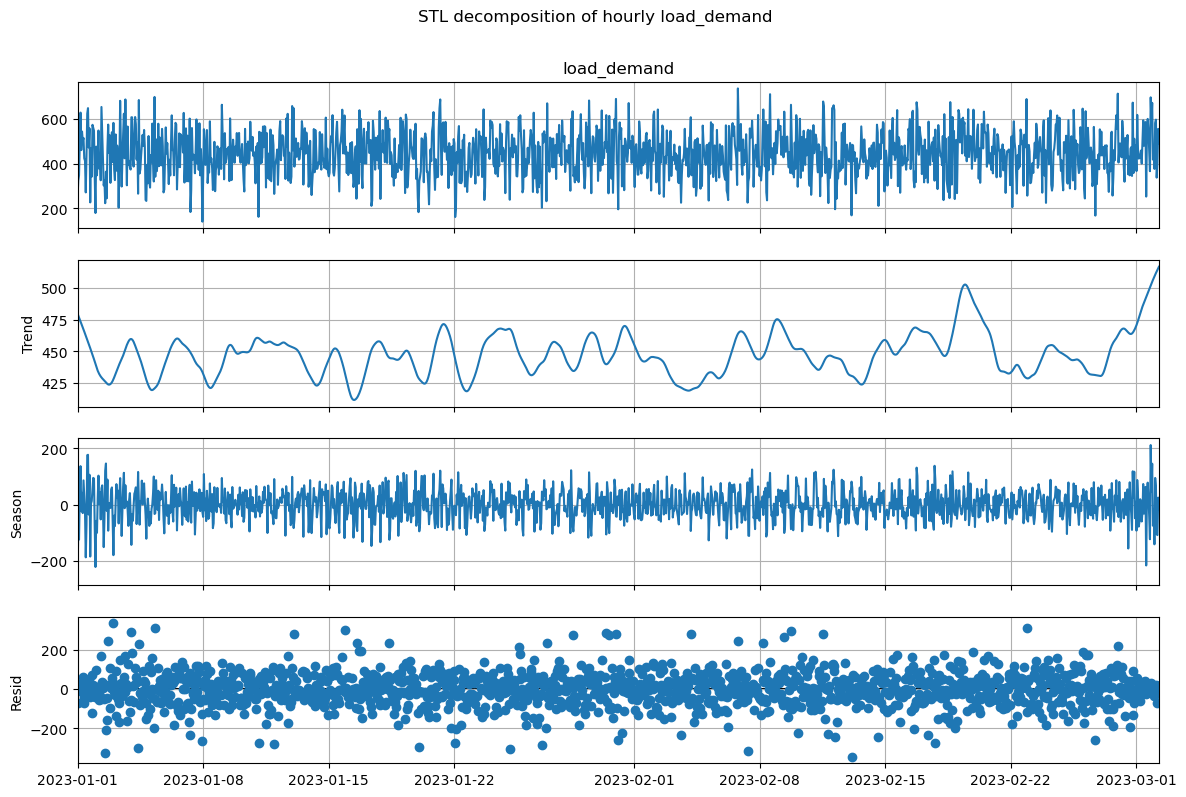

Approx. trend strength: 0.049
Approx. seasonal strength: 0.284


In [29]:
# 4.2 STL decomposition with daily seasonality

stl = STL(series_hourly, period=SEASONAL_PERIOD, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(12, 8)
plt.suptitle(f"STL decomposition of hourly {TARGET}", y=1.02)
plt.show()

remainder_var = np.var(stl_result.resid.dropna())
trend_remainder_var = np.var((stl_result.trend + stl_result.resid).dropna())
seasonal_remainder_var = np.var((stl_result.seasonal + stl_result.resid).dropna())

trend_strength = max(0, 1 - remainder_var / trend_remainder_var) if trend_remainder_var != 0 else np.nan
seasonal_strength = max(0, 1 - remainder_var / seasonal_remainder_var) if seasonal_remainder_var != 0 else np.nan

print("Approx. trend strength:", round(trend_strength, 3))
print("Approx. seasonal strength:", round(seasonal_strength, 3))

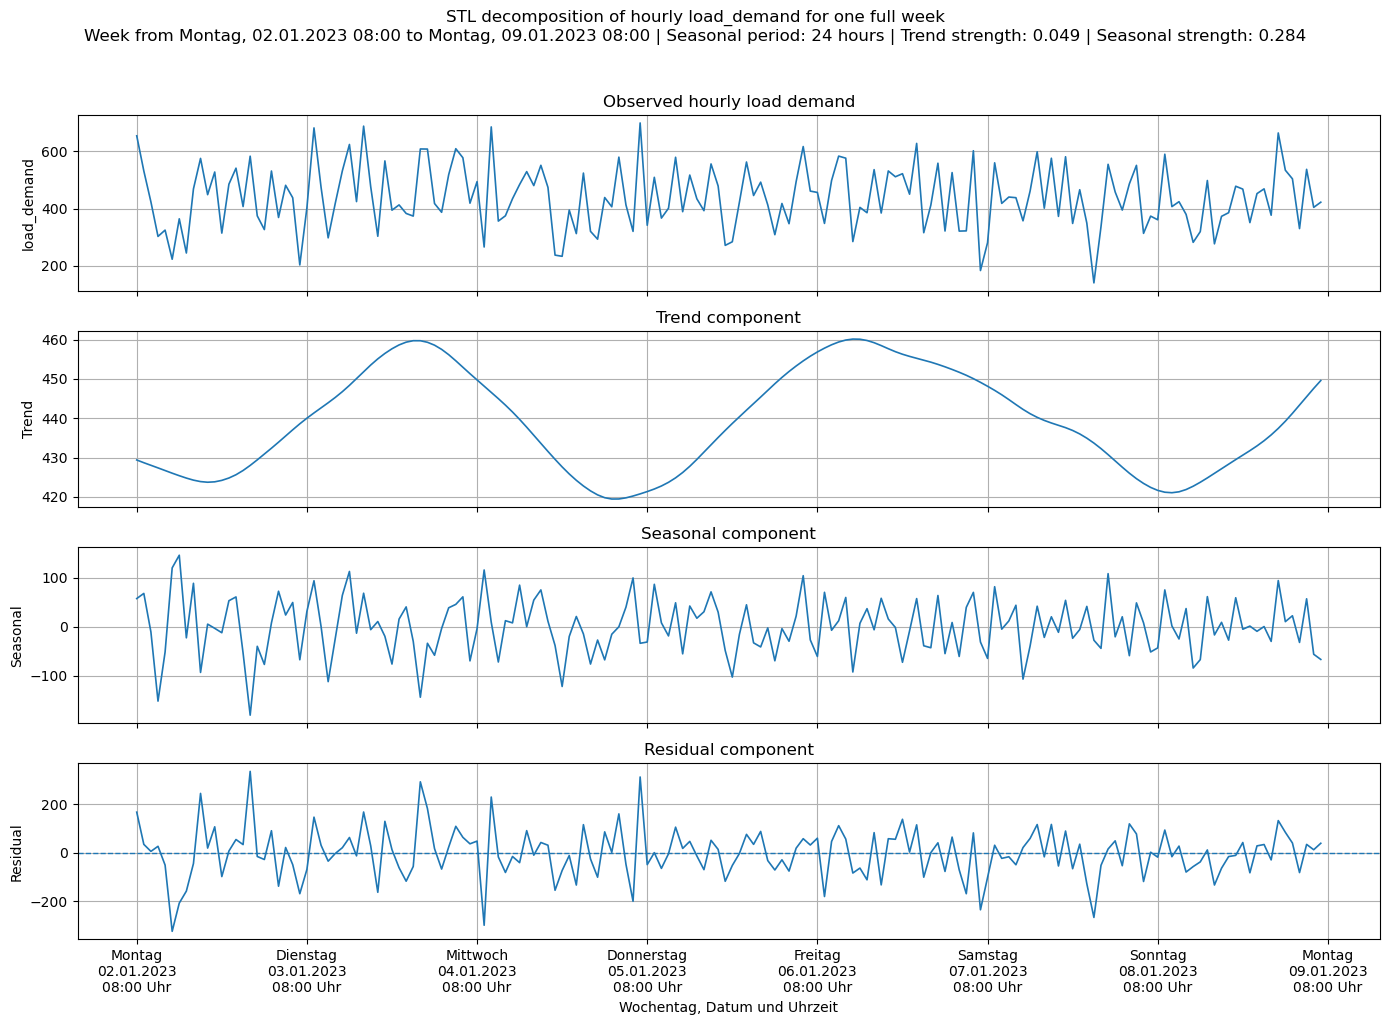

Selected week start: Montag, 02.01.2023 08:00
Selected week end:   Montag, 09.01.2023 08:00
Number of observations in selected week: 168
Expected observations for one hourly week: 168
Approx. trend strength: 0.049
Approx. seasonal strength: 0.284


,Wochentag,Datum,Uhrzeit,Observed,Trend,Seasonal,Residual
timestamp,,,,,,,
2023-01-02 08:00:00,Montag,02.01.2023,08:00,654.906819,429.392984,57.680774,167.833061
2023-01-02 09:00:00,Montag,02.01.2023,09:00,531.813834,428.698188,68.198988,34.916658
2023-01-02 10:00:00,Montag,02.01.2023,10:00,423.414285,428.047465,-10.578406,5.945225
2023-01-02 11:00:00,Montag,02.01.2023,11:00,302.471000,427.381683,-151.812674,26.901991
2023-01-02 12:00:00,Montag,02.01.2023,12:00,324.649655,426.701159,-51.492344,-50.559160
2023-01-02 13:00:00,Montag,02.01.2023,13:00,222.553392,426.034759,120.382788,-323.864155
2023-01-02 14:00:00,Montag,02.01.2023,14:00,364.184466,425.393752,146.205678,-207.414964
2023-01-02 15:00:00,Montag,02.01.2023,15:00,244.378887,424.789223,-22.534887,-157.875449
2023-01-02 16:00:00,Montag,02.01.2023,16:00,468.963544,424.266398,88.870645,-44.173500


In [30]:
# 4.2 STL decomposition for one full week
# Week starts on Monday at 08:00


# Make sure the hourly series is sorted and has a datetime index
series_hourly = series_hourly.copy()
series_hourly.index = pd.to_datetime(series_hourly.index)
series_hourly = series_hourly.sort_index()

# STL decomposition on the full hourly series
# The decomposition is estimated on the complete time series.
# Afterwards, one full week is selected for visualization.
stl = STL(series_hourly, period=SEASONAL_PERIOD, robust=True)
stl_result = stl.fit()

# Build full STL component dataframe
stl_df = pd.DataFrame({
    "Observed": series_hourly,
    "Trend": stl_result.trend,
    "Seasonal": stl_result.seasonal,
    "Residual": stl_result.resid
}).dropna()

# Find first available Monday at 08:00
first_timestamp = stl_df.index.min()

days_until_monday = (0 - first_timestamp.weekday()) % 7
week_start = first_timestamp.normalize() + pd.Timedelta(days=days_until_monday, hours=8)

# If Monday 08:00 is before the first timestamp, move to next Monday
if week_start < first_timestamp:
    week_start = week_start + pd.Timedelta(days=7)

week_end = week_start + pd.Timedelta(days=7)

# Select exactly one full week
stl_week_df = stl_df.loc[
    (stl_df.index >= week_start) &
    (stl_df.index < week_end)
].copy()

# German weekday labels
weekday_map_de = {
    0: "Montag",
    1: "Dienstag",
    2: "Mittwoch",
    3: "Donnerstag",
    4: "Freitag",
    5: "Samstag",
    6: "Sonntag"
}

# Add weekday, date and time
stl_week_df["Wochentag"] = stl_week_df.index.weekday.map(weekday_map_de)
stl_week_df["Datum"] = stl_week_df.index.strftime("%d.%m.%Y")
stl_week_df["Uhrzeit"] = stl_week_df.index.strftime("%H:%M")

# X-axis ticks: one tick per day at 08:00
tickvals = pd.date_range(start=week_start, end=week_end, freq="24h")

ticklabels = [
    f"{weekday_map_de[t.weekday()]}\n{t.strftime('%d.%m.%Y')}\n{t.strftime('%H:%M')} Uhr"
    for t in tickvals
]

# Strength calculations on the full STL decomposition
remainder_var = np.var(stl_result.resid.dropna())
trend_remainder_var = np.var((stl_result.trend + stl_result.resid).dropna())
seasonal_remainder_var = np.var((stl_result.seasonal + stl_result.resid).dropna())

trend_strength = (
    max(0, 1 - remainder_var / trend_remainder_var)
    if trend_remainder_var != 0
    else np.nan
)

seasonal_strength = (
    max(0, 1 - remainder_var / seasonal_remainder_var)
    if seasonal_remainder_var != 0
    else np.nan
)

# Plot STL components
fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(14, 10),
    sharex=True
)

axes[0].plot(stl_week_df.index, stl_week_df["Observed"], linewidth=1.2)
axes[0].set_title("Observed hourly load demand")
axes[0].set_ylabel(TARGET)

axes[1].plot(stl_week_df.index, stl_week_df["Trend"], linewidth=1.2)
axes[1].set_title("Trend component")
axes[1].set_ylabel("Trend")

axes[2].plot(stl_week_df.index, stl_week_df["Seasonal"], linewidth=1.2)
axes[2].set_title("Seasonal component")
axes[2].set_ylabel("Seasonal")

axes[3].plot(stl_week_df.index, stl_week_df["Residual"], linewidth=1.2)
axes[3].axhline(0, linestyle="--", linewidth=1)
axes[3].set_title("Residual component")
axes[3].set_ylabel("Residual")
axes[3].set_xlabel("Wochentag, Datum und Uhrzeit")

# Set x-axis labels with weekday, date and time
axes[3].set_xticks(tickvals)
axes[3].set_xticklabels(ticklabels, rotation=0)

# Main title
fig.suptitle(
    f"STL decomposition of hourly {TARGET} for one full week\n"
    f"Week from {weekday_map_de[week_start.weekday()]}, {week_start.strftime('%d.%m.%Y %H:%M')} "
    f"to {weekday_map_de[week_end.weekday()]}, {week_end.strftime('%d.%m.%Y %H:%M')} | "
    f"Seasonal period: {SEASONAL_PERIOD} hours | "
    f"Trend strength: {trend_strength:.3f} | "
    f"Seasonal strength: {seasonal_strength:.3f}",
    y=1.02
)

plt.tight_layout()
plt.show()

# Documentation output
print(f"Selected week start: {weekday_map_de[week_start.weekday()]}, {week_start.strftime('%d.%m.%Y %H:%M')}")
print(f"Selected week end:   {weekday_map_de[week_end.weekday()]}, {week_end.strftime('%d.%m.%Y %H:%M')}")
print(f"Number of observations in selected week: {len(stl_week_df)}")
print("Expected observations for one hourly week:", 24 * 7)
print("Approx. trend strength:", round(trend_strength, 3))
print("Approx. seasonal strength:", round(seasonal_strength, 3))

# Optional table with weekday information
display(
    stl_week_df[
        ["Wochentag", "Datum", "Uhrzeit", "Observed", "Trend", "Seasonal", "Residual"]
    ].head(10)
)

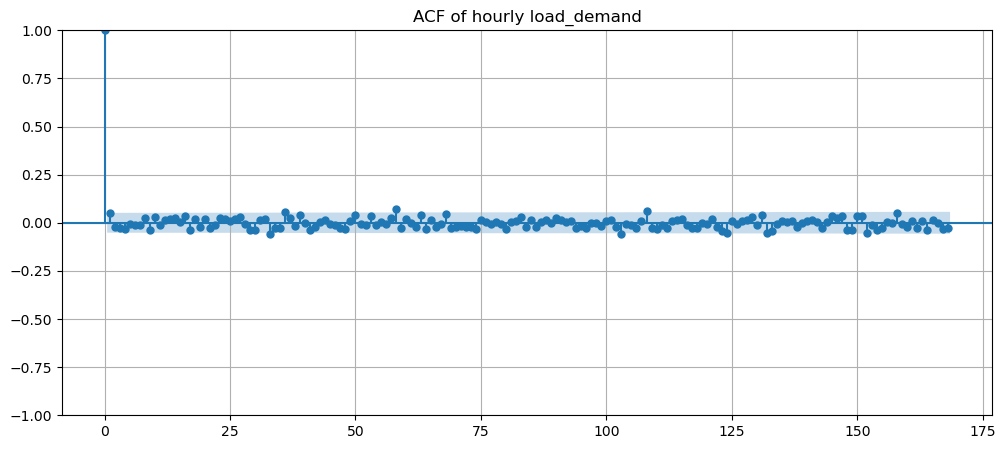

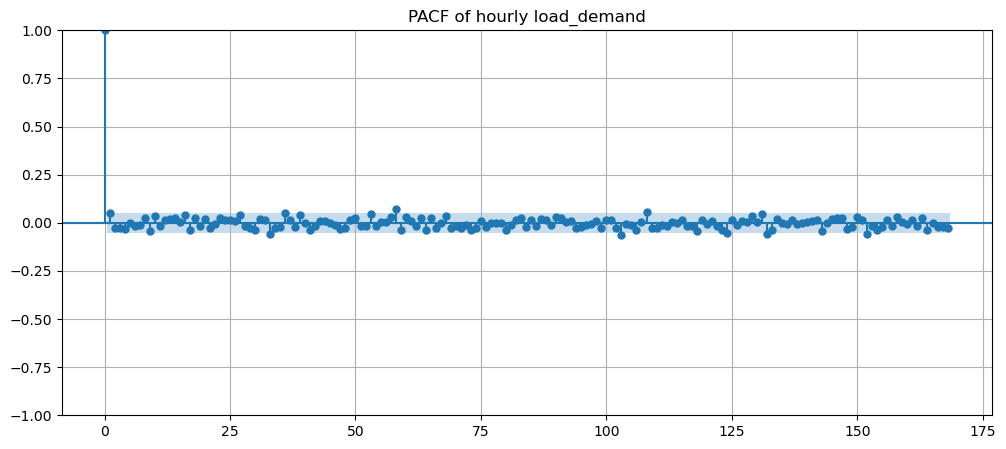

In [31]:
# 4.3 ACF and PACF

max_lags = min(7 * SEASONAL_PERIOD, len(series_hourly) // 2 - 1)

fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(series_hourly.dropna(), lags=max_lags, ax=ax)
plt.title(f"ACF of hourly {TARGET}")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
plot_pacf(series_hourly.dropna(), lags=max_lags, ax=ax, method="ywm")
plt.title(f"PACF of hourly {TARGET}")
plt.show()

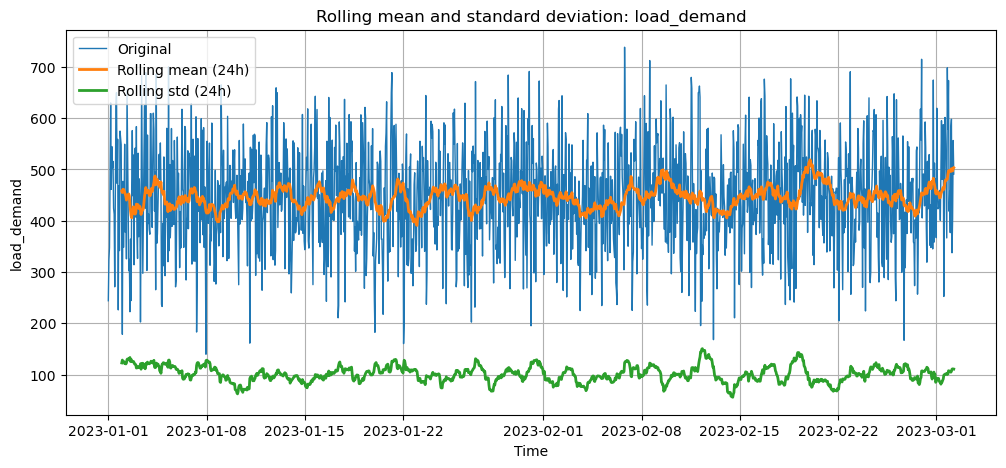

In [32]:
# 4.4 Rolling mean and rolling standard deviation

rolling_window = SEASONAL_PERIOD

rolling_mean = series_hourly.rolling(rolling_window).mean()
rolling_std = series_hourly.rolling(rolling_window).std()

plt.figure()
plt.plot(series_hourly.index, series_hourly, label="Original", linewidth=1)
plt.plot(rolling_mean.index, rolling_mean, label=f"Rolling mean ({rolling_window}h)", linewidth=2)
plt.plot(rolling_std.index, rolling_std, label=f"Rolling std ({rolling_window}h)", linewidth=2)
plt.title(f"Rolling mean and standard deviation: {TARGET}")
plt.xlabel("Time")
plt.ylabel(TARGET)
plt.legend()
plt.show()

In [33]:
# 4.5 Augmented Dickey-Fuller test

def run_adf_test(series, name="series"):
    series = pd.Series(series).dropna()
    result = adfuller(series, autolag="AIC")
    output = {
        "series": name,
        "ADF statistic": result[0],
        "p-value": result[1],
        "used lags": result[2],
        "observations": result[3],
    }
    for key, value in result[4].items():
        output[f"critical value {key}"] = value
    return pd.Series(output)

adf_original = run_adf_test(series_hourly, "original hourly series")
adf_diff = run_adf_test(series_hourly.diff(), "first difference")
adf_seasonal_diff = run_adf_test(
    series_hourly.diff(SEASONAL_PERIOD),
    f"seasonal difference lag {SEASONAL_PERIOD}"
)

adf_results = pd.DataFrame([adf_original, adf_diff, adf_seasonal_diff])
display(adf_results)

,series,ADF statistic,p-value,used lags,observations,critical value 1%,critical value 5%,critical value 10%
0,original hourly series,-36.242663,0.000000e+00,0,1446,-3.434880,-2.863541,-2.567835
1,first difference,-13.370784,5.203062e-25,24,1421,-3.434960,-2.863576,-2.567854
2,seasonal difference lag 24,-11.706515,1.524329e-21,23,1399,-3.435033,-2.863608,-2.567871


## 5. Chronological train-test split

The split is chronological because future observations must not be used to train a forecasting model.


Total observations: 1447
Train observations: 1157
Test observations: 290
Train period: 2023-01-01 00:00:00 to 2023-02-18 04:00:00
Test period: 2023-02-18 05:00:00 to 2023-03-02 06:00:00


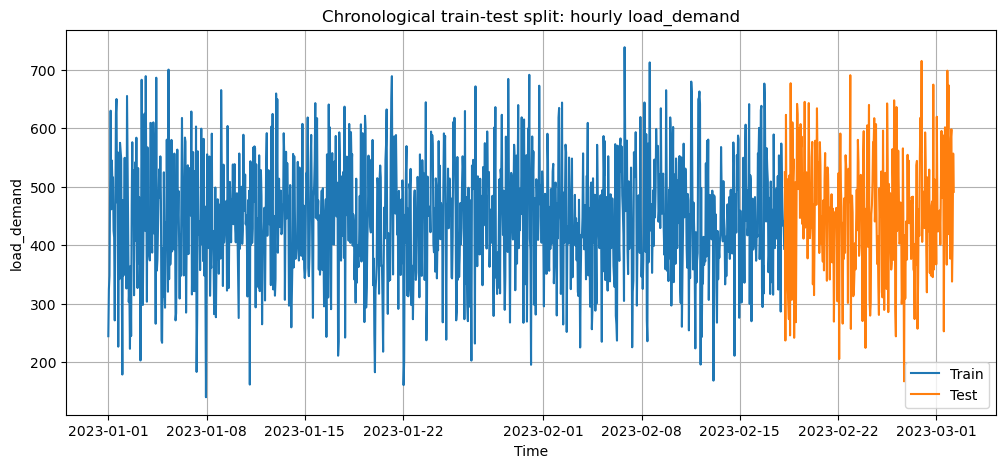

In [34]:
# 5. Train-test split

n = len(series_hourly)
test_n = int(np.ceil(n * TEST_SIZE))

train = series_hourly.iloc[:-test_n]
test = series_hourly.iloc[-test_n:]

print("Total observations:", n)
print("Train observations:", len(train))
print("Test observations:", len(test))
print("Train period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())

plt.figure()
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.title(f"Chronological train-test split: hourly {TARGET}")
plt.xlabel("Time")
plt.ylabel(TARGET)
plt.legend()
plt.show()

## 6. Evaluation and diagnostics helpers

The same metric and diagnostic functions are used for all three models.


In [35]:
# 6. Evaluation and diagnostics helpers

def calculate_metrics(y_true, y_pred, model_name):
    y_true = pd.Series(y_true).astype(float)
    y_pred = pd.Series(y_pred, index=y_true.index).astype(float)

    valid = ~(y_true.isna() | y_pred.isna())
    y_true = y_true[valid]
    y_pred = y_pred[valid]

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    return {
        "model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    }


def plot_forecast(train, test, forecast, model_name):
    forecast = pd.Series(forecast, index=test.index).astype(float)

    plt.figure(figsize=(12, 5))
    plt.plot(train.index, train, label="Train", linewidth=1)
    plt.plot(test.index, test, label="Test", linewidth=1)
    plt.plot(test.index, forecast, label=f"{model_name} forecast", linewidth=2)
    plt.title(f"{model_name} forecast vs actual: hourly {TARGET}")
    plt.xlabel("Time")
    plt.ylabel(TARGET)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def residual_diagnostics(y_true, y_pred, model_name, lags=48):
    # Convert true and predicted values to aligned numeric Series
    y_true = pd.Series(y_true).astype(float)
    y_pred = pd.Series(y_pred, index=y_true.index).astype(float)

    # Keep only valid observations
    valid = ~(y_true.isna() | y_pred.isna())
    y_true = y_true[valid]
    y_pred = y_pred[valid]

    # Calculate residuals
    residuals = (y_true - y_pred).dropna()

    print(f"Residual summary for {model_name}:")
    display(residuals.describe().to_frame("residuals"))

    # Residuals over time
    plt.figure(figsize=(12, 5))
    plt.plot(residuals.index, residuals, linewidth=1)
    plt.axhline(0, color="black", linestyle="--", linewidth=1)
    plt.title(f"Residuals over time: {model_name}")
    plt.xlabel("Time")
    plt.ylabel("Residual")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Residual distribution with density curve
    plt.figure(figsize=(10, 5))
    sns.histplot(
        residuals,
        bins=40,
        kde=True,
        stat="count"
    )
    plt.axvline(0, color="black", linestyle="--", linewidth=1)
    plt.title(f"Residual distribution with density curve: {model_name}")
    plt.xlabel("Residual")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ACF of residuals
    acf_lags = min(lags, len(residuals) // 2 - 1)

    if acf_lags > 0:
        fig, ax = plt.subplots(figsize=(12, 5))
        plot_acf(residuals, lags=acf_lags, ax=ax)
        plt.title(f"ACF of residuals: {model_name}")
        plt.tight_layout()
        plt.show()

    # Ljung-Box test
    lb_lags = sorted(set([
        max(1, min(24, len(residuals) // 3)),
        max(1, min(48, len(residuals) // 3))
    ]))

    lb = acorr_ljungbox(residuals, lags=lb_lags, return_df=True)

    print("Ljung-Box test for residual autocorrelation:")
    display(lb)

    return residuals

## 7. Model 1: Holt-Winters / Exponential Smoothing

Holt-Winters is used first as a transparent seasonal benchmark.  
The model below uses additive trend and additive daily seasonality with `seasonal_periods = 24`.


                       ExponentialSmoothing Model Results                       
Dep. Variable:              load_demand   No. Observations:                 1157
Model:             ExponentialSmoothing   SSE                       13211032.770
Optimized:                         True   AIC                          10865.825
Trend:                         Additive   BIC                          11007.325
Seasonal:                      Additive   AICC                         10867.476
Seasonal Periods:                    24   Date:                 Tue, 30 Jun 2026
Box-Cox:                          False   Time:                         17:20:38
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level               0.0403844                alpha                 True
smoothing_trend          

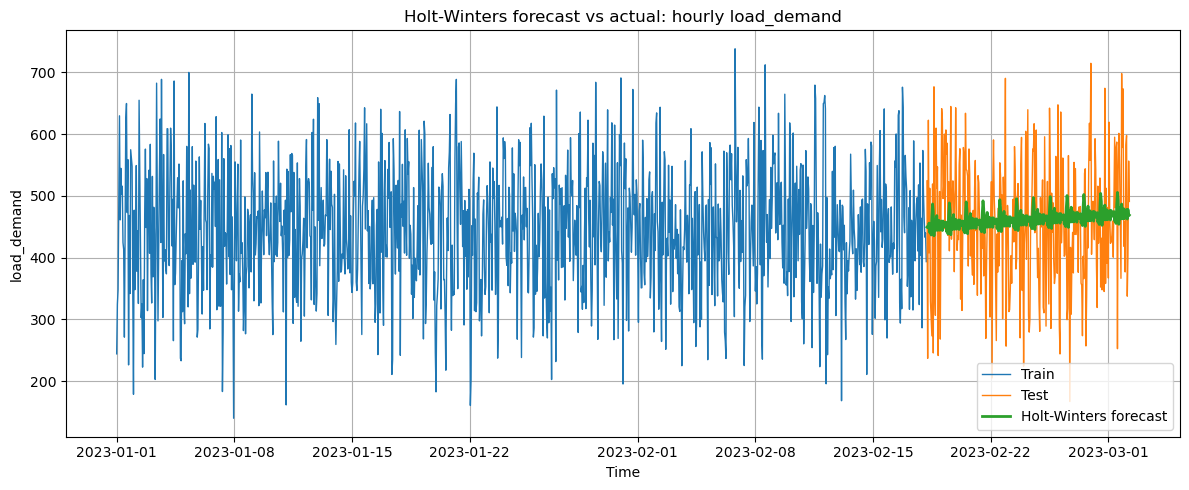

Residual summary for Holt-Winters:


,residuals
count,290.000000
mean,-6.979070
std,105.751146
min,-290.502420
25%,-80.673389
50%,-2.470049
75%,64.781763
max,255.135357


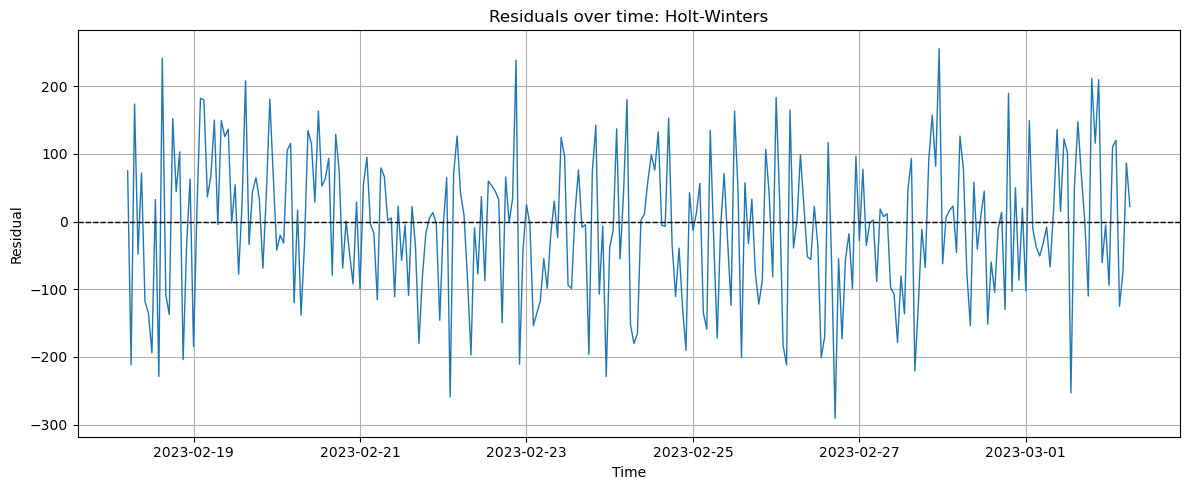

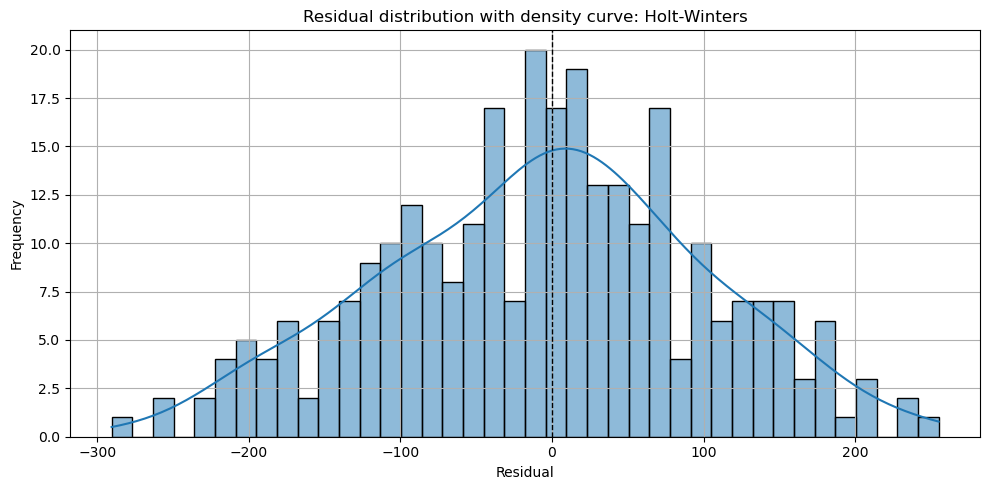

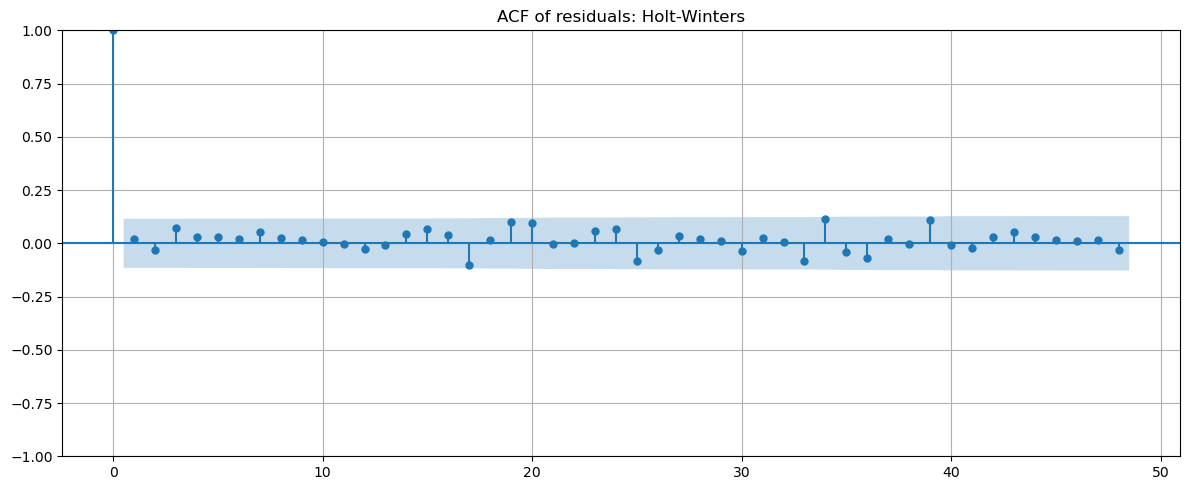

Ljung-Box test for residual autocorrelation:


,lb_stat,lb_pvalue
24,18.173251,0.794524
48,37.242870,0.869319


In [36]:
# 7. Holt-Winters model

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=SEASONAL_PERIOD,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(optimized=True)

print(hw_fit.summary())

hw_forecast = pd.Series(
    hw_fit.forecast(len(test)).values,
    index=test.index,
    name="Holt-Winters"
)

plot_forecast(train, test, hw_forecast, "Holt-Winters")

hw_metrics = calculate_metrics(test, hw_forecast, "Holt-Winters")
hw_residuals = residual_diagnostics(test, hw_forecast, "Holt-Winters")

## 8. Model 2: SARIMA

The SARIMAX implementation is used without external regressors, so it functions as a SARIMA model in this notebook.

The starting specification is intentionally moderate:

- non-seasonal order: `(1, 1, 1)`
- seasonal order: `(1, 0, 1, 24)`

These parameters can be tuned after inspecting ACF, PACF and residual diagnostics.


                                     SARIMAX Results                                      
Dep. Variable:                        load_demand   No. Observations:                 1157
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 24)   Log Likelihood               -6825.106
Date:                            Tue, 30 Jun 2026   AIC                          13660.213
Time:                                    17:20:41   BIC                          13685.363
Sample:                                01-01-2023   HQIC                         13669.715
                                     - 02-18-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0437      0.028      1.538      0.124      -0.012       0.099
ma.L1         -1.0000      1.704   

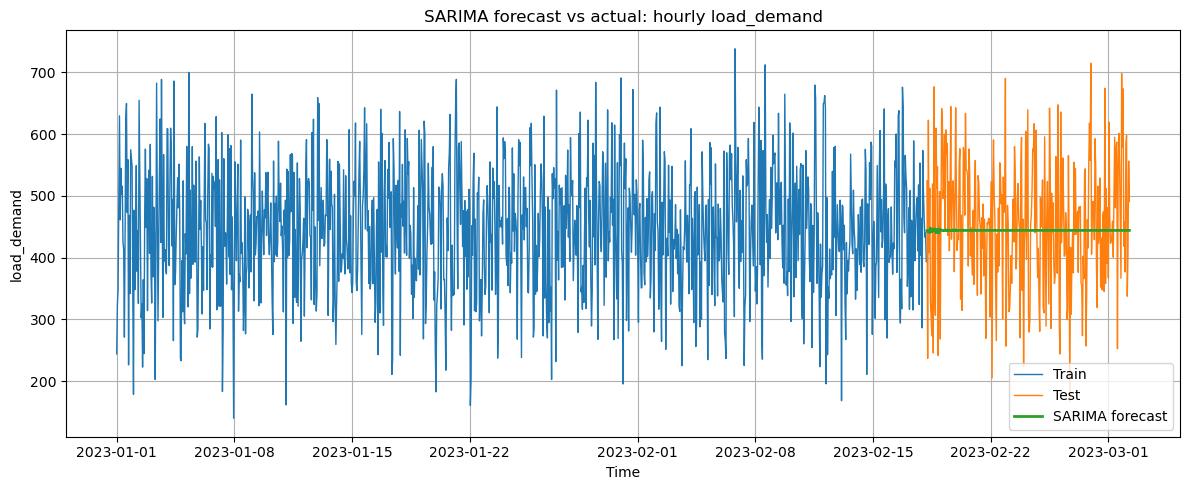

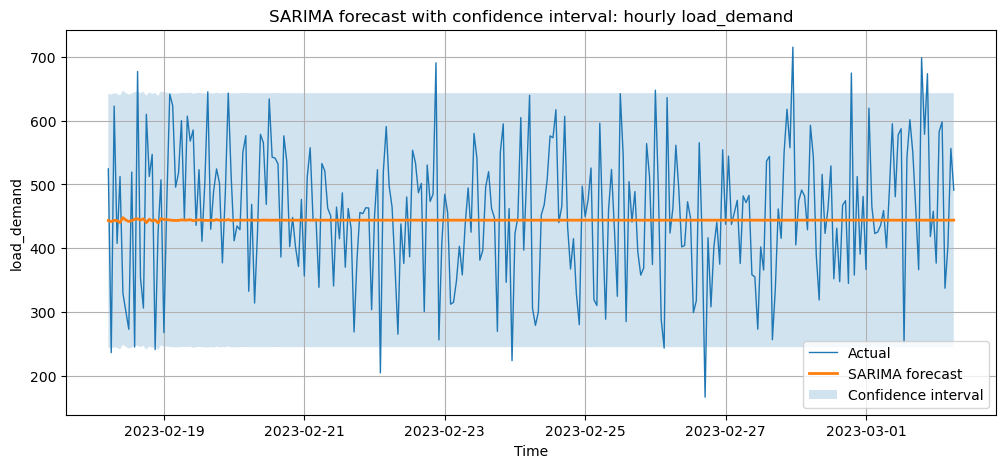

Residual summary for SARIMA:


,residuals
count,290.000000
mean,11.871068
std,104.505331
min,-277.202454
25%,-57.670658
50%,17.809786
75%,81.494994
max,270.715724


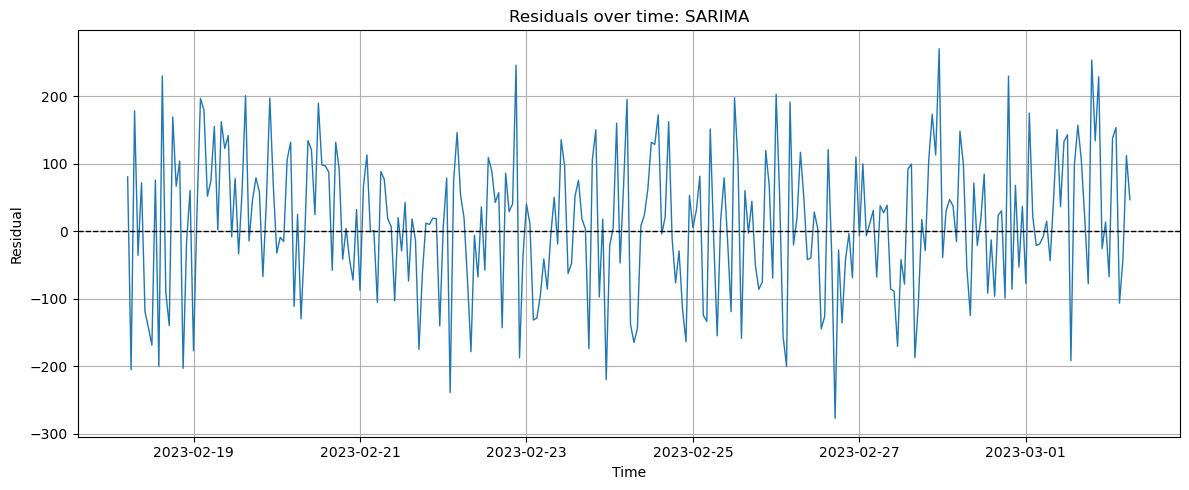

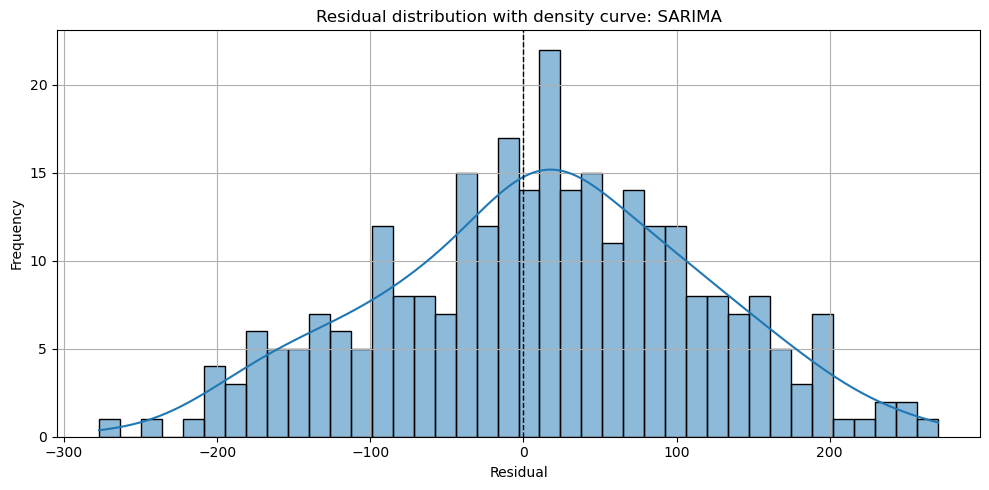

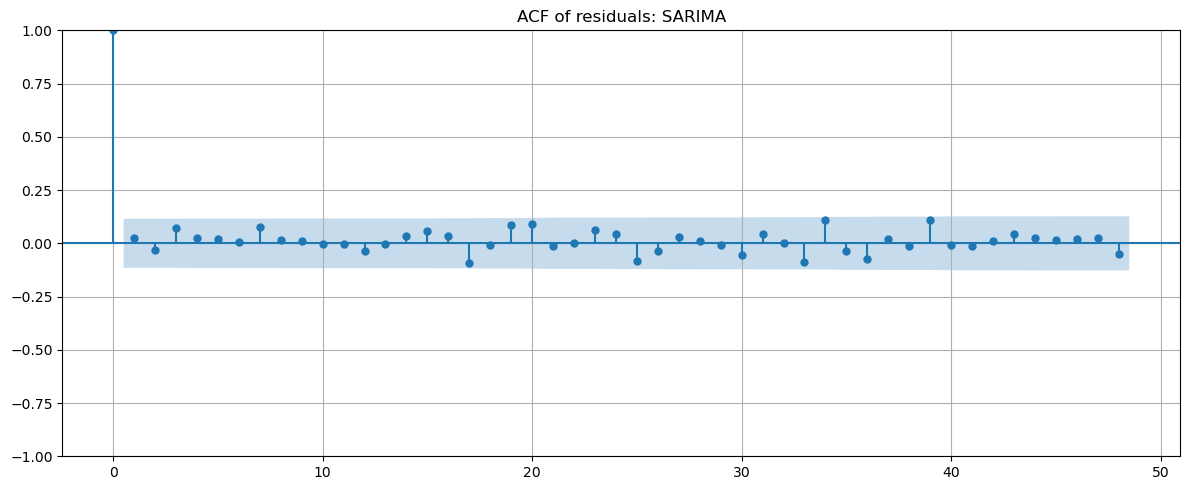

Ljung-Box test for residual autocorrelation:


,lb_stat,lb_pvalue
24,15.819922,0.894466
48,35.369808,0.912089


In [37]:
# 8. SARIMA

sarima_order = (1, 1, 1)
sarima_seasonal_order = (1, 0, 1, SEASONAL_PERIOD)

sarima_model = SARIMAX(
    train,
    order=sarima_order,
    seasonal_order=sarima_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False, maxiter=200)

print(sarima_fit.summary())

sarima_forecast_result = sarima_fit.get_forecast(steps=len(test))
sarima_forecast = pd.Series(
    sarima_forecast_result.predicted_mean.values,
    index=test.index,
    name="SARIMA"
)

sarima_ci = sarima_forecast_result.conf_int()
sarima_ci.index = test.index

plot_forecast(train, test, sarima_forecast, "SARIMA")

plt.figure()
plt.plot(test.index, test, label="Actual", linewidth=1)
plt.plot(test.index, sarima_forecast, label="SARIMA forecast", linewidth=2)
plt.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Confidence interval"
)
plt.title(f"SARIMA forecast with confidence interval: hourly {TARGET}")
plt.xlabel("Time")
plt.ylabel(TARGET)
plt.legend()
plt.show()

sarima_metrics = calculate_metrics(test, sarima_forecast, "SARIMA")
sarima_residuals = residual_diagnostics(test, sarima_forecast, "SARIMA")

## 9. Model 3: Prophet

Prophet can model trend and multiple seasonal effects.  
For hourly microgrid demand data, daily and weekly seasonalities are relevant candidates.

If Prophet is not installed, the notebook skips this section and continues with Holt-Winters and SARIMA/SARIMAX.


17:20:41 - cmdstanpy - INFO - Chain [1] start processing
17:20:42 - cmdstanpy - INFO - Chain [1] done processing


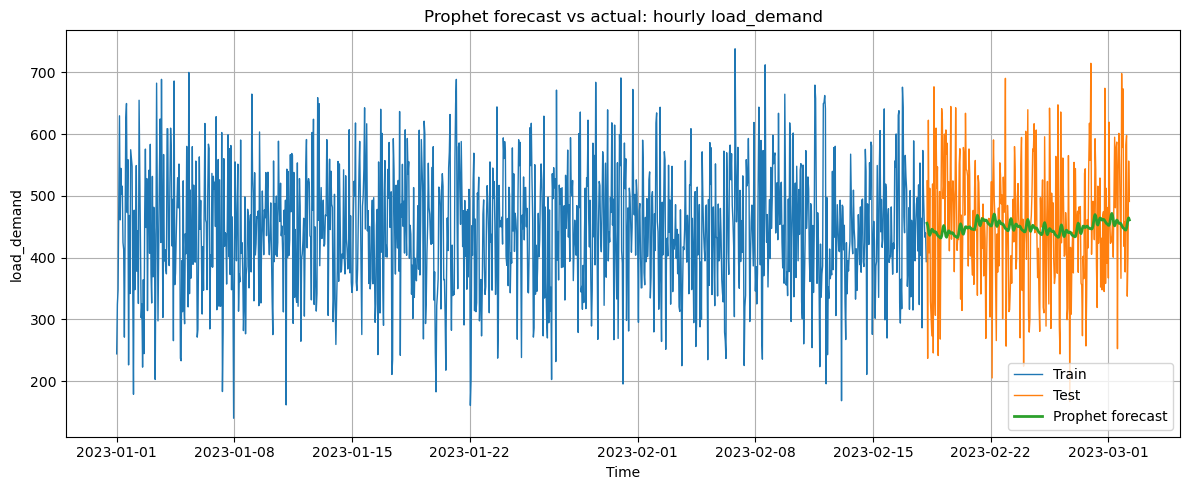

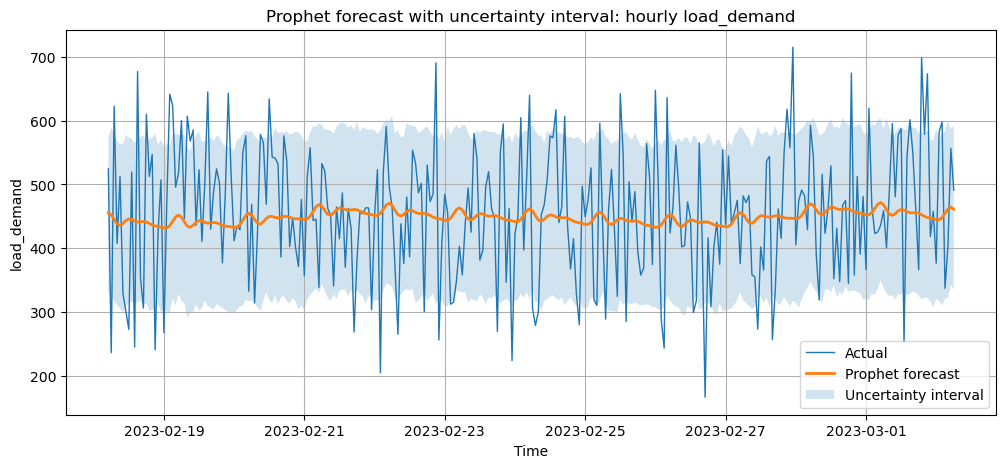

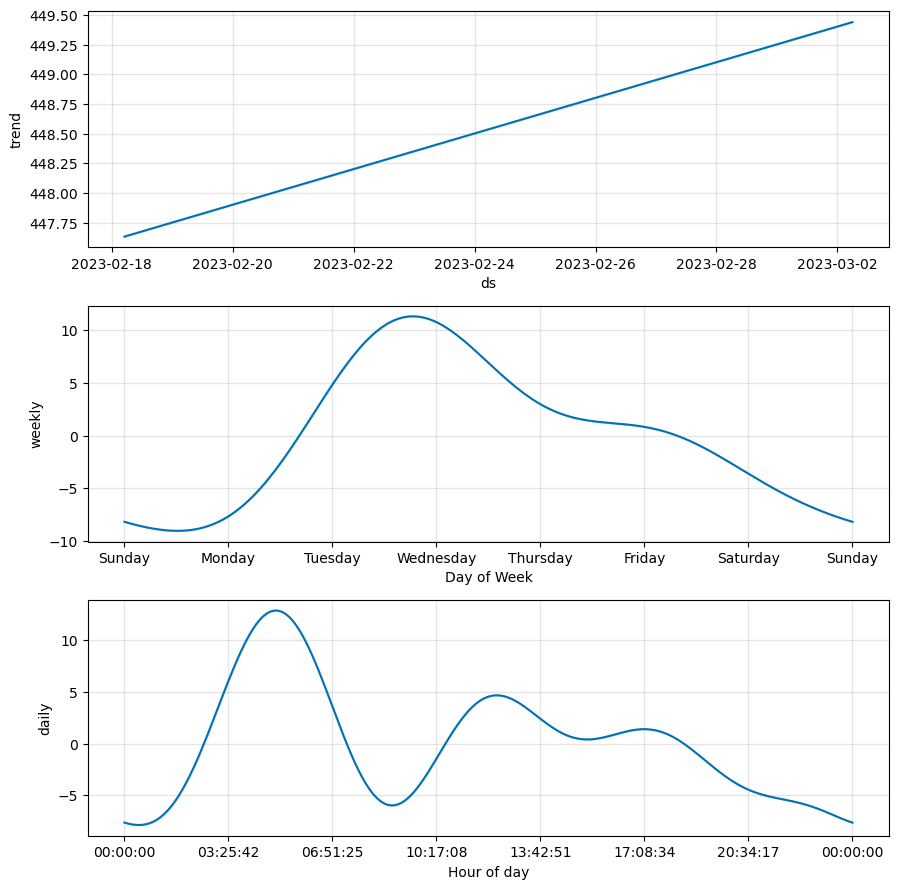

Residual summary for Prophet:


,residuals
count,290.000000
mean,7.251985
std,104.941608
min,-274.590954
25%,-61.708092
50%,9.393066
75%,77.326517
max,267.910681


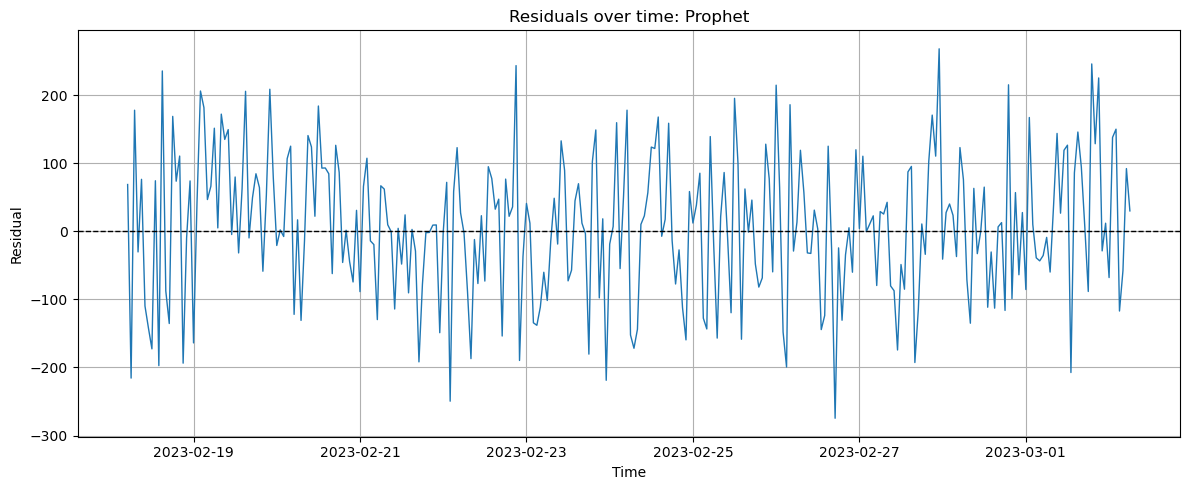

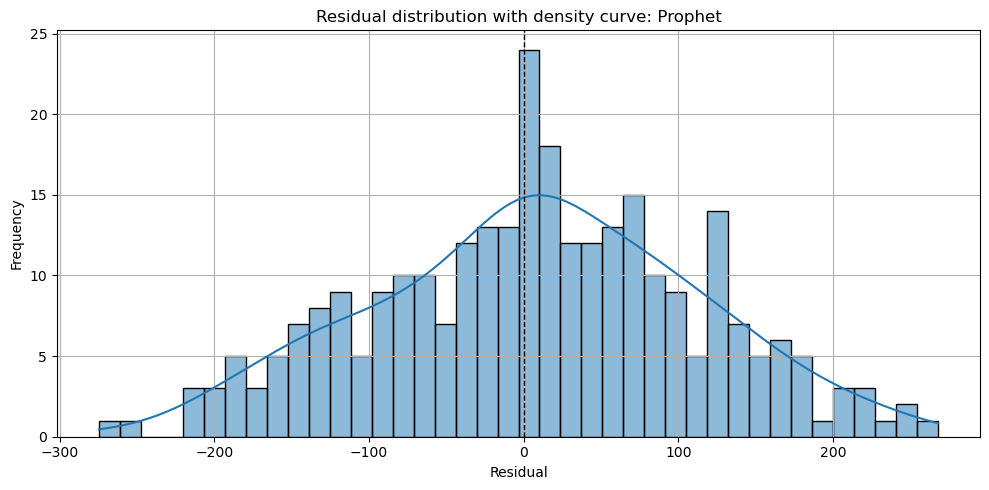

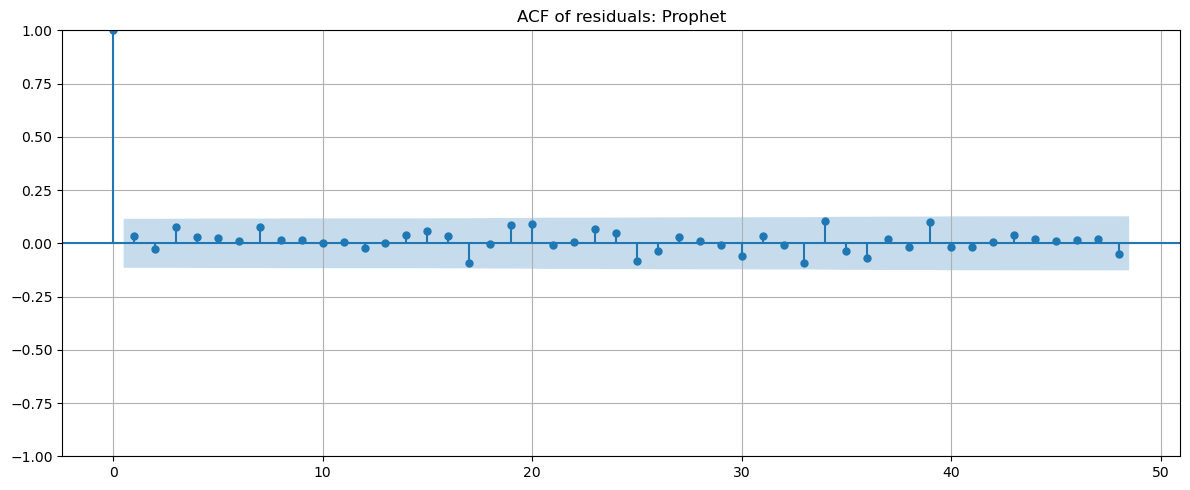

Ljung-Box test for residual autocorrelation:


,lb_stat,lb_pvalue
24,16.590817,0.865581
48,35.206978,0.915305


In [38]:
# 9. Prophet model

if PROPHET_AVAILABLE:
    prophet_train = train.reset_index()
    prophet_train.columns = ["ds", "y"]

    prophet_model = Prophet(
        daily_seasonality=True,
        weekly_seasonality=True,
        yearly_seasonality=False,
        seasonality_mode="additive"
    )

    prophet_model.fit(prophet_train)

    future = pd.DataFrame({"ds": test.index})
    prophet_pred = prophet_model.predict(future)
    prophet_forecast = pd.Series(
        prophet_pred["yhat"].values,
        index=test.index,
        name="Prophet"
    )

    plot_forecast(train, test, prophet_forecast, "Prophet")

    plt.figure()
    plt.plot(test.index, test, label="Actual", linewidth=1)
    plt.plot(test.index, prophet_forecast, label="Prophet forecast", linewidth=2)
    plt.fill_between(
        test.index,
        prophet_pred["yhat_lower"].values,
        prophet_pred["yhat_upper"].values,
        alpha=0.2,
        label="Uncertainty interval"
    )
    plt.title(f"Prophet forecast with uncertainty interval: hourly {TARGET}")
    plt.xlabel("Time")
    plt.ylabel(TARGET)
    plt.legend()
    plt.show()

    prophet_model.plot_components(prophet_pred)
    plt.show()

    prophet_metrics = calculate_metrics(test, prophet_forecast, "Prophet")
    prophet_residuals = residual_diagnostics(test, prophet_forecast, "Prophet")
else:
    prophet_forecast = None
    prophet_metrics = None
    print("Prophet skipped because it is not installed.")
    print("Run: !pip install prophet")


## 10. Model comparison

This section compares Holt-Winters, SARIMA/SARIMAX and Prophet using the same test set.


,model,MAE,MSE,RMSE,model_order,rank_by_RMSE
0,Holt-Winters,84.344887,11193.449232,105.799098,1,3.0
1,SARIMA,84.308707,11024.626586,104.998222,2,1.0
2,Prophet,83.877417,11027.357365,105.011225,3,2.0


,model,MAE,MSE,RMSE,model_order,rank_by_RMSE
0,SARIMA,84.308707,11024.626586,104.998222,2,1.0
1,Prophet,83.877417,11027.357365,105.011225,3,2.0
2,Holt-Winters,84.344887,11193.449232,105.799098,1,3.0


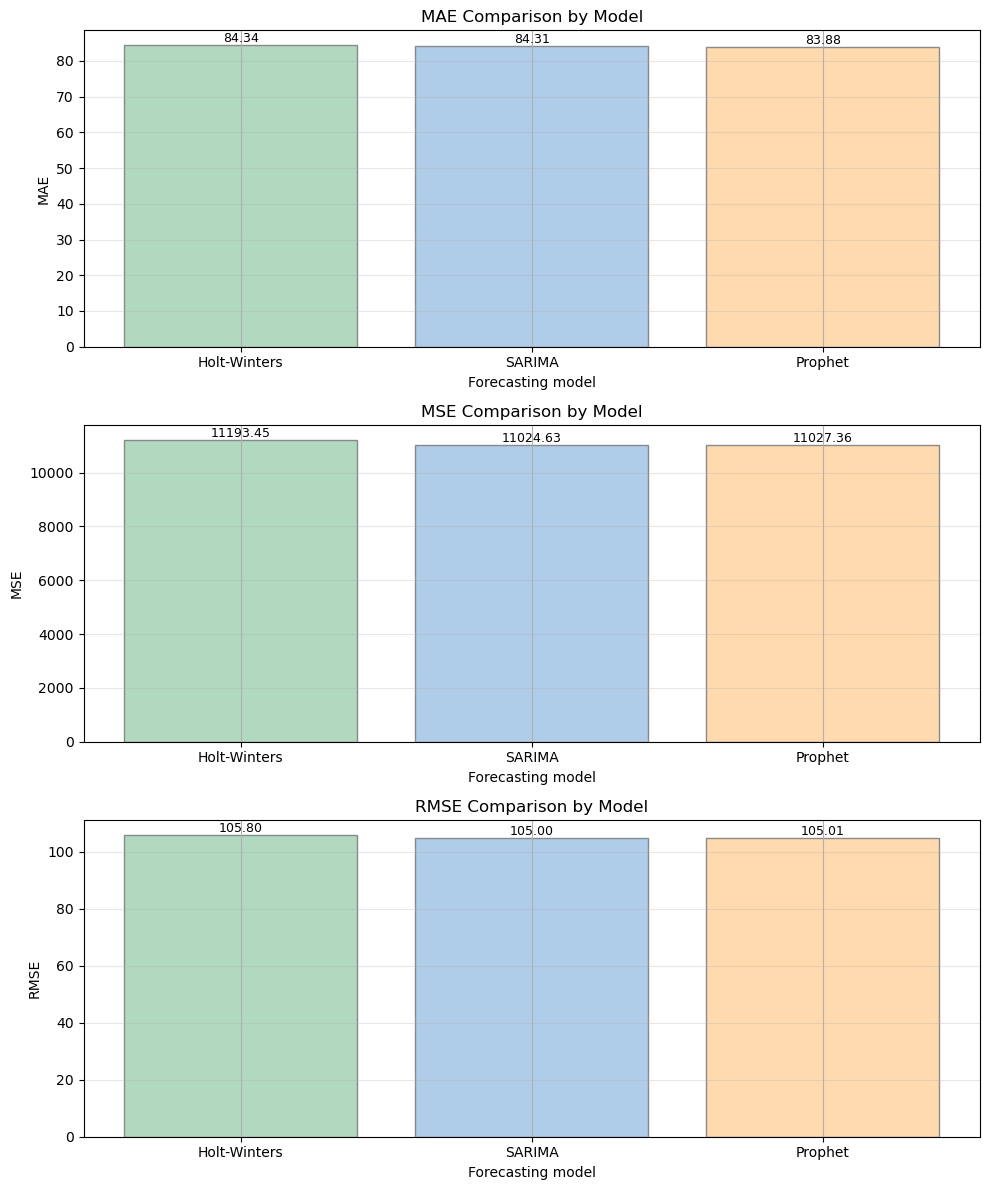

In [39]:
# 10. Model comparison - MAE, MSE and RMSE with pastel colors
# Build metrics dataframe

metrics_list = [hw_metrics, sarima_metrics]

if prophet_metrics is not None:
    metrics_list.append(prophet_metrics)

metrics_df = pd.DataFrame(metrics_list)

model_order = {
    "Holt-Winters": 1,
    "SARIMA": 2,
    "Prophet": 3
}

metrics_df["model_order"] = metrics_df["model"].map(model_order)
metrics_df["rank_by_RMSE"] = metrics_df["RMSE"].rank(method="min")
metrics_df = metrics_df.sort_values("model_order").reset_index(drop=True)

# Display model comparison tables
display(metrics_df)

metrics_ranked_df = metrics_df.sort_values("RMSE").reset_index(drop=True)
display(metrics_ranked_df)

# Select metrics for visualization
metric_columns = ["MAE", "MSE", "RMSE"]

plot_df = metrics_df.set_index("model")[metric_columns]

# Consistent pastel colors for each model
model_colors = {
    "Holt-Winters": "#A8D5BA",
    "SARIMA": "#A7C7E7",
    "Prophet": "#FFD6A5"
}

colors = [model_colors[model] for model in plot_df.index]

# Create separate plots because MSE has a much larger scale
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 12)
)

for ax, metric in zip(axes, metric_columns):
    bars = ax.bar(
        plot_df.index,
        plot_df[metric],
        color=colors,
        alpha=0.9,
        edgecolor="gray"
    )

    ax.set_title(f"{metric} Comparison by Model")
    ax.set_xlabel("Forecasting model")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3)

    # Add value labels above bars
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()

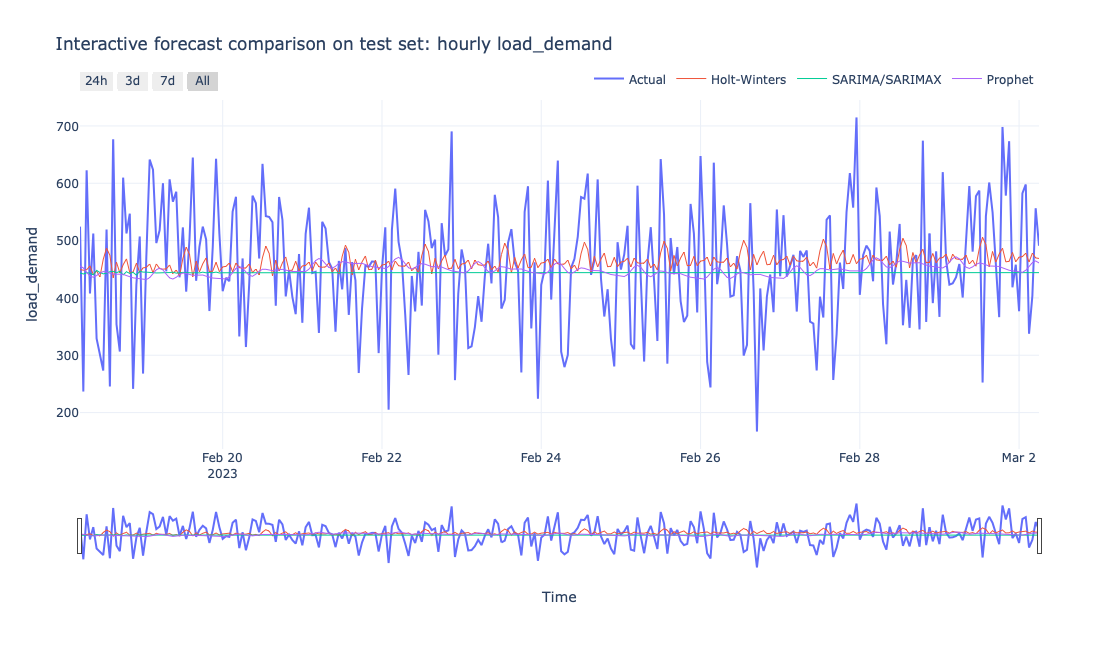

In [41]:
# 10.1 Interactive forecast comparison plot


# Safety helper: convert forecasts to one-dimensional arrays
def to_1d_array(values):
    return np.asarray(values).reshape(-1)

# Actual test values
actual_values = to_1d_array(test)

# Create interactive figure
fig = go.Figure()

# Actual values
fig.add_trace(
    go.Scatter(
        x=test.index,
        y=actual_values,
        mode="lines",
        name="Actual",
        line=dict(width=2)
    )
)

# Holt-Winters forecast
fig.add_trace(
    go.Scatter(
        x=test.index,
        y=to_1d_array(hw_forecast),
        mode="lines",
        name="Holt-Winters",
        line=dict(width=1)
    )
)

# SARIMA/SARIMAX forecast
fig.add_trace(
    go.Scatter(
        x=test.index,
        y=to_1d_array(sarima_forecast),
        mode="lines",
        name="SARIMA/SARIMAX",
        line=dict(width=1)
    )
)

# Prophet forecast, only if available
if prophet_forecast is not None:
    fig.add_trace(
        go.Scatter(
            x=test.index,
            y=to_1d_array(prophet_forecast),
            mode="lines",
            name="Prophet",
            line=dict(width=1)
        )
    )

# Layout settings
fig.update_layout(
    title=f"Interactive forecast comparison on test set: hourly {TARGET}",
    xaxis_title="Time",
    yaxis_title=TARGET,
    hovermode="x unified",
    template="plotly_white",
    width=1100,
    height=650,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    )
)

# Zoom buttons and range slider
fig.update_xaxes(
    rangeslider=dict(visible=True),
    rangeselector=dict(
        buttons=list([
            dict(count=24, label="24h", step="hour", stepmode="backward"),
            dict(count=3, label="3d", step="day", stepmode="backward"),
            dict(count=7, label="7d", step="day", stepmode="backward"),
            dict(step="all", label="All")
        ])
    )
)

fig.show()
